## Proyecto
# EDA - Exploratory data analysis

### Ingrid Carolina Ortíz Mejicanos

## 1. Estructura del proyecto y repositorio
Comandos ejecutados en la terminal de VSCode:
```bash
pip install cookiecutter-data-science
ccds https://github.com/drivendataorg/cookiecutter-data-science
git init
git add .
git commit -m "Estructura cookiecutter + gitignore"
git remote add origin https://github.com/carormex/predict-future-sales-eda.git
git push -u origin main
```

In [1]:
import sys, warnings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
from statsmodels.tsa.stattools import adfuller, kpss, acf, pacf
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import STL

warnings.filterwarnings("ignore")

# Rutas del proyecto
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "data" / "raw").exists())
RAW = ROOT / "data" / "raw"
FIGS = ROOT / "reports" / "figures"
FIGS.mkdir(parents=True, exist_ok=True)
print("Carpeta de trabajo:", Path.cwd())
print("Raíz del proyecto:", ROOT)
print("Contenido de la raíz:", sorted(p.name for p in ROOT.iterdir()))
sys.path.insert(0, str(ROOT))
from predict_future_sales_eda.traducciones import traducir_categorias, traducir_tiendas

# Estilo de gráficas
sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.figsize": (12, 5), "axes.titlesize": 13, "axes.titleweight": "bold"})
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")

def guardar(nombre):
    """Guarda la figura actual en reports/figures."""
    plt.savefig(FIGS / f"{nombre}.png", dpi=120, bbox_inches="tight")

print("Proyecto:", ROOT)
print("Archivos en data/raw:", sorted(p.name for p in RAW.glob("*.csv")))

2026-11-15 20:06:31.743 -06:00 | INFO     | predict_future_sales_eda.config:<module>:11 - PROJ_ROOT path is: C:\Users\icome\Documents\predict-future-sales-eda


Carpeta de trabajo: c:\Users\icome\Documents\predict-future-sales-eda\notebooks
Raíz del proyecto: c:\Users\icome\Documents\predict-future-sales-eda
Contenido de la raíz: ['.env', '.git', '.gitignore', 'Makefile', 'README.md', 'data', 'docs', 'models', 'notebooks', 'predict-future-sales-eda', 'predict_future_sales_eda', 'pyproject.toml', 'references', 'reports', 'requirements.txt']
Proyecto: c:\Users\icome\Documents\predict-future-sales-eda
Archivos en data/raw: ['item_categories.csv', 'items.csv', 'sales_train.csv', 'sample_submission.csv', 'shops.csv', 'test.csv']


## 2. Comprensión inicial del dataset
### 2a. Carga de archivos y primeras filas

In [2]:
sales = pd.read_csv(RAW / "sales_train.csv")
items = pd.read_csv(RAW / "items.csv")
categories_raw = pd.read_csv(RAW / "item_categories.csv")
shops_raw = pd.read_csv(RAW / "shops.csv")
test = pd.read_csv(RAW / "test.csv")

tablas = {"sales_train": sales, "items": items, "item_categories": categories_raw,
          "shops": shops_raw, "test": test}

for nombre, df in tablas.items():
    print(f"=== {nombre} ===")
    display(df.head())

=== sales_train ===


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
0,02.01.2013,0,59,22154,999.00,1.00
1,03.01.2013,0,25,2552,899.00,1.00
2,05.01.2013,0,25,2552,899.00,-1.00
3,06.01.2013,0,25,2554,"1,709.05",1.00
4,15.01.2013,0,25,2555,"1,099.00",1.00


=== items ===


,item_name,item_id,item_category_id
0,! ВО ВЛАСТИ НАВАЖДЕНИЯ (ПЛАСТ.) D,0,40
1,!ABBYY FineReader 12 Professional Edition Full...,1,76
2,***В ЛУЧАХ СЛАВЫ (UNV) D,2,40
3,***ГОЛУБАЯ ВОЛНА (Univ) D,3,40
4,***КОРОБКА (СТЕКЛО) D,4,40


=== item_categories ===


,item_category_name,item_category_id
0,PC - Гарнитуры/Наушники,0
1,Аксессуары - PS2,1
2,Аксессуары - PS3,2
3,Аксессуары - PS4,3
4,Аксессуары - PSP,4


=== shops ===


,shop_name,shop_id
0,"!Якутск Орджоникидзе, 56 фран",0
1,"!Якутск ТЦ ""Центральный"" фран",1
2,"Адыгея ТЦ ""Мега""",2
3,"Балашиха ТРК ""Октябрь-Киномир""",3
4,"Волжский ТЦ ""Волга Молл""",4


=== test ===


,ID,shop_id,item_id
0,0,5,5037
1,1,5,5320
2,2,5,5233
3,3,5,5232
4,4,5,5268


In [3]:
categories = traducir_categorias(categories_raw)
shops = traducir_tiendas(shops_raw)

display(categories.head(10))
display(shops.head(10))

,item_category_name,item_category_id,categoria_grupo,categoria_nombre
0,PC - Гарнитуры/Наушники,0,PC,PC - Auriculares/Headsets
1,Аксессуары - PS2,1,Accesorios,Accesorios - PS2
2,Аксессуары - PS3,2,Accesorios,Accesorios - PS3
3,Аксессуары - PS4,3,Accesorios,Accesorios - PS4
4,Аксессуары - PSP,4,Accesorios,Accesorios - PSP
5,Аксессуары - PSVita,5,Accesorios,Accesorios - PSVita
6,Аксессуары - XBOX 360,6,Accesorios,Accesorios - XBOX 360
7,Аксессуары - XBOX ONE,7,Accesorios,Accesorios - XBOX ONE
8,Билеты (Цифра),8,Entradas,Entradas (Digital)
9,Доставка товара,9,Envíos,Envío de productos


,shop_name,shop_id,ciudad,tienda_nombre,tienda_tipo
0,"!Якутск Орджоникидзе, 56 фран",0,Yakutsk,Yakutsk Ordzhonikidze 56 (franquicia),Física
1,"!Якутск ТЦ ""Центральный"" фран",1,Yakutsk,Yakutsk CC Tsentralny (franquicia),Física
2,"Адыгея ТЦ ""Мега""",2,Adygea,Adygea CC Mega,Física
3,"Балашиха ТРК ""Октябрь-Киномир""",3,Balashikha,Balashikha CCE Oktyabr-Kinomir,Física
4,"Волжский ТЦ ""Волга Молл""",4,Volzhsky,Volzhsky CC Volga Mall,Física
5,"Вологда ТРЦ ""Мармелад""",5,Vologda,Vologda CCE Marmelad,Física
6,"Воронеж (Плехановская, 13)",6,Voronezh,Voronezh (Plekhanovskaya 13),Física
7,"Воронеж ТРЦ ""Максимир""",7,Voronezh,Voronezh CCE Maksimir,Física
8,"Воронеж ТРЦ Сити-Парк ""Град""",8,Voronezh,Voronezh CCE City-Park Grad,Física
9,Выездная Торговля,9,Itinerante,Ventas itinerantes,Itinerante


### 2b. Tamaño de cada tabla

In [4]:
tamanos = pd.DataFrame({n: {"filas": d.shape[0], "columnas": d.shape[1]} for n, d in tablas.items()}).T
tamanos

,filas,columnas
sales_train,2935849,6
items,22170,3
item_categories,84,2
shops,60,2
test,214200,3


### 2c. Descripción de las columnas

| Columna | Tabla | Descripción |
|---|---|---|
| `date` | sales_train | Fecha de la transacción (texto `dd.mm.aaaa`) |
| `date_block_num` | sales_train | Mes consecutivo: 0 = ene-2013 … 33 = oct-2015 |
| `shop_id` | sales_train, shops, test | Identificador de la tienda (sucursal) |
| `item_id` | sales_train, items, test | Identificador del producto |
| `item_price` | sales_train | Precio unitario del producto ese día (rublos) |
| `item_cnt_day` | sales_train | Unidades vendidas ese día; los negativos son devoluciones |
| `item_name` | items | Nombre del producto (en ruso) |
| `item_category_id` | items, item_categories | Identificador de la categoría del producto |
| `item_category_name` | item_categories | Nombre de la categoría (en ruso; traducida en `categoria_nombre`) |
| `shop_name` | shops | Nombre de la tienda: ciudad + centro comercial (traducida en `tienda_nombre`) |

**Variable construida:** `revenue = item_price × item_cnt_day` (ingreso en rublos).

**Variable objetivo:** `item_cnt_month`, la suma mensual de `item_cnt_day` por par tienda-producto. Es lo que se predice para noviembre de 2015 (`date_block_num = 34`).

### 2d. Rango temporal

In [5]:
fechas = pd.to_datetime(sales["date"], format="%d.%m.%Y")
print("Fecha mínima :", fechas.min().date())
print("Fecha máxima :", fechas.max().date())
print("Días cubiertos:", (fechas.max() - fechas.min()).days + 1)
print("Meses cubiertos:", sales["date_block_num"].nunique(),
      f"(date_block_num de {sales['date_block_num'].min()} a {sales['date_block_num'].max()})")

Fecha mínima : 2013-01-01
Fecha máxima : 2015-10-31
Días cubiertos: 1034
Meses cubiertos: 34 (date_block_num de 0 a 33)


**Interpretación (sección 2):** el train tiene **2,935,849 transacciones diarias** en **60 tiendas**, con un catálogo de **22,170 productos** agrupados en **84 categorías**. Los datos van del **01-ene-2013 al 31-oct-2015**: 1,034 días, o sea **34 meses completos**. Para el forecasting esto da solo **34 observaciones mensuales**, menos de 3 ciclos anuales. Esa es una limitación importante: los modelos estacionales (SARIMA, Holt-Winters) necesitan al menos 2 ciclos completos de 12 meses para estimar la estacionalidad. El test tiene **214,200 pares tienda-producto** a predecir para noviembre de 2015.

## 3. Validación de la estructura de los datos
### 3a. Tipos de datos

In [6]:
tipos = pd.DataFrame({
    "tipo_pandas": sales.dtypes.astype(str),
    "tipo_conceptual": ["Fecha (texto)", "Numérica discreta (índice de mes)", "Categórica (ID)",
                        "Categórica (ID)", "Numérica continua", "Numérica discreta"],
    "valores_unicos": sales.nunique(),
})
tipos

,tipo_pandas,tipo_conceptual,valores_unicos
date,object,Fecha (texto),1034
date_block_num,int64,Numérica discreta (índice de mes),34
shop_id,int64,Categórica (ID),60
item_id,int64,Categórica (ID),21807
item_price,float64,Numérica continua,19993
item_cnt_day,float64,Numérica discreta,198


**Observación:** `date` viene como texto, así que hay que convertirla a fecha. `shop_id` e `item_id` vienen como números, pero son **identificadores categóricos**: no tiene sentido sumarlos ni promediarlos. Los dejamos como enteros porque así las agrupaciones son más rápidas.

### 3b. Conversión de `date` a datetime

In [7]:
sales["date"] = pd.to_datetime(sales["date"], format="%d.%m.%Y")
print(sales.dtypes)
sales[["date"]].head(3)

date              datetime64[ns]
date_block_num             int64
shop_id                    int64
item_id                    int64
item_price               float64
item_cnt_day             float64
dtype: object


,date
0,2013-01-02
1,2013-01-03
2,2013-01-05


### 3c. Frecuencia temporal: días sin ventas y consistencia de `date_block_num`

In [8]:
# ¿Hay días sin ventas?
calendario = pd.date_range(sales["date"].min(), sales["date"].max(), freq="D")
dias_con_venta = sales["date"].unique()
dias_sin_venta = calendario.difference(dias_con_venta)
print(f"Días en el calendario: {len(calendario)}")
print(f"Días con ventas:       {len(dias_con_venta)}")
print(f"Días sin ventas:       {len(dias_sin_venta)}")

trans_dia = sales.groupby("date").size()
print(f"Transacciones por día: mínimo {trans_dia.min():,}, mediana {trans_dia.median():,.0f}, máximo {trans_dia.max():,}")

# ¿date_block_num coincide con la fecha?
bloque_esperado = (sales["date"].dt.year - 2013) * 12 + sales["date"].dt.month - 1
print(f"\nRegistros donde date_block_num NO coincide con la fecha: {(bloque_esperado != sales['date_block_num']).sum()}")

mapa = sales.groupby("date_block_num")["date"].agg(["min", "max", "count"])
mapa.columns = ["primer_día", "último_día", "transacciones"]
mapa

Días en el calendario: 1034
Días con ventas:       1034
Días sin ventas:       0
Transacciones por día: mínimo 1,123, mediana 2,590, máximo 9,434

Registros donde date_block_num NO coincide con la fecha: 0


,primer_día,último_día,transacciones
date_block_num,,,
0,2013-01-01,2013-01-31,115690
1,2013-02-01,2013-02-28,108613
2,2013-03-01,2013-03-31,121347
3,2013-04-01,2013-04-30,94109
4,2013-05-01,2013-05-31,91759
5,2013-06-01,2013-06-30,100403
6,2013-07-01,2013-07-31,100548
7,2013-08-01,2013-08-31,104772
8,2013-09-01,2013-09-30,96137


**Interpretación (sección 3):**
- **Tipos:** después de la conversión, `date` es `datetime64`. `item_price` es numérica continua, `item_cnt_day` numérica discreta, y `shop_id` / `item_id` son identificadores categóricos.
- **Días sin ventas:** hay **0 días sin ventas** a nivel cadena: los 1,034 días del calendario tienen transacciones (entre ~1,100 y ~9,400 por día). La serie diaria total está **completa**, sin huecos que imputar. Ojo: a nivel de una tienda o producto individual sí hay muchos días sin venta, porque la serie diaria por par tienda-producto es muy dispersa, casi todo ceros.
- **Consistencia:** `date_block_num` coincide con la fecha en el **100 %** de los registros. Cada bloque cubre del día 1 al último día de su mes.
- **Frecuencia recomendada: mensual.** (1) La variable objetivo de la competencia es mensual. (2) Agregar a nivel mes reduce el ruido y la dispersión de la serie diaria tienda-producto. (3) Permite modelar la estacionalidad anual (período 12) con modelos como SARIMA o Holt-Winters. La frecuencia **diaria** se usará solo para la serie total, para estudiar los ciclos por día de la semana; la **semanal** como vista intermedia de tendencia.

## 4. Análisis de valores faltantes y duplicados
### 4a. Valores nulos

In [9]:
nulos = pd.concat({n: pd.DataFrame({"nulos": d.isna().sum(), "% nulos": d.isna().mean() * 100})
                   for n, d in tablas.items()})
print("Total de valores nulos en todo el dataset:", int(nulos["nulos"].sum()))
nulos

Total de valores nulos en todo el dataset: 0


nulos  % nulos
sales_train     date                    0     0.00
                date_block_num          0     0.00
                shop_id                 0     0.00
                item_id                 0     0.00
                item_price              0     0.00
                item_cnt_day            0     0.00
items           item_name               0     0.00
                item_id                 0     0.00
                item_category_id        0     0.00
item_categories item_category_name      0     0.00
                item_category_id        0     0.00
shops           shop_name               0     0.00
                shop_id                 0     0.00
test            ID                      0     0.00
                shop_id                 0     0.00
                item_id                 0     0.00

### 4b. Valores inválidos (no nulos)

In [10]:
n = len(sales)
invalidos = pd.DataFrame({
    "registros": [(sales["item_price"] <= 0).sum(),
                  (sales["item_cnt_day"] < 0).sum(),
                  (sales["item_cnt_day"] == 0).sum(),
                  (sales["item_price"] > 100_000).sum(),
                  (sales["item_cnt_day"] >= 1_000).sum()]},
    index=["Precio <= 0", "Cantidad negativa (devolución)", "Cantidad = 0",
           "Precio > 100,000 rublos", "Cantidad >= 1,000 unidades en un día"])
invalidos["% del total"] = invalidos["registros"] / n * 100
display(invalidos)

print("Registro con precio <= 0:")
display(sales[sales["item_price"] <= 0])

print("Registros extremos (precio > 100,000 o cantidad >= 1,000):")
display(sales[(sales["item_price"] > 100_000) | (sales["item_cnt_day"] >= 1_000)]
        .merge(items[["item_id", "item_name", "item_category_id"]], on="item_id"))

vendidas = sales.loc[sales["item_cnt_day"] > 0, "item_cnt_day"].sum()
devueltas = -sales.loc[sales["item_cnt_day"] < 0, "item_cnt_day"].sum()
print(f"Unidades devueltas: {devueltas:,.0f} de {vendidas:,.0f} vendidas ({devueltas / vendidas * 100:.2f} %)")

,registros,% del total
Precio <= 0,1,0.00
Cantidad negativa (devolución),7356,0.25
Cantidad = 0,0,0.00
"Precio > 100,000 rublos",1,0.00
"Cantidad >= 1,000 unidades en un día",2,0.00


Registro con precio <= 0:


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
484683,2013-05-15,4,32,2973,-1.00,1.00


Registros extremos (precio > 100,000 o cantidad >= 1,000):


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,item_name,item_category_id
0,2013-12-13,11,12,6066,"307,980.00",1.00,Radmin 3 - 522 лиц.,75
1,2015-01-15,24,12,20949,4.00,"1,000.00",Фирменный пакет майка 1С Интерес белый (34*42)...,71
2,2015-10-28,33,12,11373,0.91,"2,169.00",Доставка до пункта выдачи (Boxberry),9


Unidades devueltas: 7,541 de 3,655,747 vendidas (0.21 %)


### 4c. Registros duplicados y tiendas repetidas

In [11]:
print(f"Filas duplicadas exactas: {sales.duplicated().sum()}")
display(sales[sales.duplicated(keep=False)].sort_values(["date", "shop_id", "item_id"]))

print(f"Registros con misma (fecha, tienda, producto) pero distinto precio/cantidad: "
      f"{sales.duplicated(['date', 'shop_id', 'item_id']).sum() - sales.duplicated().sum()}")
print(f"item_id repetidos en items.csv: {items['item_id'].duplicated().sum()}")
print(f"item_category_id repetidos: {categories['item_category_id'].duplicated().sum()}")

Filas duplicadas exactas: 6


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day
76961,2013-01-05,0,54,20130,149.00,1.00
76962,2013-01-05,0,54,20130,149.00,1.00
1435365,2014-02-23,13,50,3423,999.00,1.00
1435367,2014-02-23,13,50,3423,999.00,1.00
1496765,2014-03-23,14,21,3423,999.00,1.00
1496766,2014-03-23,14,21,3423,999.00,1.00
1671872,2014-05-01,16,50,3423,999.00,1.00
1671873,2014-05-01,16,50,3423,999.00,1.00
1866322,2014-07-12,18,25,3423,999.00,1.00
1866340,2014-07-12,18,25,3423,999.00,1.00


Registros con misma (fecha, tienda, producto) pero distinto precio/cantidad: 22
item_id repetidos en items.csv: 0
item_category_id repetidos: 0


In [12]:
import re

def normalizar(nombre):
    """Quita signos, la marca de franquicia ('фран') y caracteres mal codificados."""
    nombre = nombre.lower().replace("!", "").replace("фран", "").replace("²", "").replace("?", "")
    return re.sub(r"[^\w]", "", nombre)

shops["nombre_norm"] = shops["shop_name"].apply(normalizar)
repetidas = shops[shops.duplicated("nombre_norm", keep=False)].sort_values("nombre_norm")
display(repetidas[["shop_id", "shop_name", "tienda_nombre"]])

# ¿En qué meses vendió cada una? (si no se traslapan, es la misma tienda con otro ID)
meses_tienda = sales.groupby("shop_id")["date_block_num"].agg(["min", "max", "nunique"])
meses_tienda.columns = ["primer_mes", "último_mes", "meses_activos"]
display(meses_tienda.loc[[0, 57, 1, 58, 10, 11]])
print("De estas tiendas, aparecen en test.csv:", sorted(set(test["shop_id"]) & {0, 57, 1, 58, 10, 11}))

,shop_id,shop_name,tienda_nombre
10,10,Жуковский ул. Чкалова 39м?,Zhukovsky calle Chkalova 39m?
11,11,Жуковский ул. Чкалова 39м²,Zhukovsky calle Chkalova 39m²
0,0,"!Якутск Орджоникидзе, 56 фран",Yakutsk Ordzhonikidze 56 (franquicia)
57,57,"Якутск Орджоникидзе, 56",Yakutsk Ordzhonikidze 56
1,1,"!Якутск ТЦ ""Центральный"" фран",Yakutsk CC Tsentralny (franquicia)
58,58,"Якутск ТЦ ""Центральный""",Yakutsk CC Tsentralny


,primer_mes,último_mes,meses_activos
shop_id,,,
0,0,1,2
57,2,33,32
1,0,1,2
58,2,33,32
10,0,33,33
11,25,25,1


De estas tiendas, aparecen en test.csv: [10, 57, 58]


### 4d. Estrategia de limpieza aplicada

In [13]:
df = sales.drop_duplicates().copy()

# 1) Tiendas duplicadas -> se unifican hacia el ID que aparece en test.csv
mapa_tiendas = {0: 57, 1: 58, 11: 10}
df["shop_id"] = df["shop_id"].replace(mapa_tiendas)
test_c = test.copy()
test_c["shop_id"] = test_c["shop_id"].replace(mapa_tiendas)

# 2) Precio <= 0 -> se imputa con la mediana del mismo producto, tienda y mes
mask = df["item_price"] <= 0
ref = df[~mask].groupby(["item_id", "shop_id", "date_block_num"])["item_price"].median()
df.loc[mask, "item_price"] = [ref.get(tuple(k), np.nan)
                              for k in df.loc[mask, ["item_id", "shop_id", "date_block_num"]].values]

# 3) Outliers extremos -> se eliminan (2 registros)
df = df[(df["item_price"] <= 100_000) & (df["item_cnt_day"] < 1_000)]

# 4) Variable de ingreso + catálogos en español
df["revenue"] = df["item_price"] * df["item_cnt_day"]
df = (df.merge(items[["item_id", "item_name", "item_category_id"]], on="item_id", how="left")
        .merge(categories[["item_category_id", "categoria_grupo", "categoria_nombre"]], on="item_category_id", how="left")
        .merge(shops[["shop_id", "ciudad", "tienda_nombre", "tienda_tipo"]], on="shop_id", how="left"))

print(f"Registros originales:      {len(sales):,}")
print(f"Registros después limpieza: {len(df):,}  (eliminados: {len(sales) - len(df)})")
print(f"Tiendas únicas: {sales['shop_id'].nunique()} -> {df['shop_id'].nunique()}")
print(f"Nulos tras el merge: {df.isna().sum().sum()}")
df.head()

Registros originales:      2,935,849
Registros después limpieza: 2,935,840  (eliminados: 9)
Tiendas únicas: 60 -> 57
Nulos tras el merge: 0


,date,date_block_num,shop_id,item_id,item_price,item_cnt_day,revenue,item_name,item_category_id,categoria_grupo,categoria_nombre,ciudad,tienda_nombre,tienda_tipo
0,2013-01-02,0,59,22154,999.00,1.00,999.00,ЯВЛЕНИЕ 2012 (BD),37,Cine,Cine - Blu-Ray,Yaroslavl,Yaroslavl CC Altair,Física
1,2013-01-03,0,25,2552,899.00,1.00,899.00,DEEP PURPLE The House Of Blue Light LP,58,Música,Música - Vinilo,Moscú,Moscú CCE Atrium,Física
2,2013-01-05,0,25,2552,899.00,-1.00,-899.00,DEEP PURPLE The House Of Blue Light LP,58,Música,Música - Vinilo,Moscú,Moscú CCE Atrium,Física
3,2013-01-06,0,25,2554,"1,709.05",1.00,"1,709.05",DEEP PURPLE Who Do You Think We Are LP,58,Música,Música - Vinilo,Moscú,Moscú CCE Atrium,Física
4,2013-01-15,0,25,2555,"1,099.00",1.00,"1,099.00",DEEP PURPLE 30 Very Best Of 2CD (Фирм.),56,Música,Música - CD de sello (importado),Moscú,Moscú CCE Atrium,Física


**Interpretación (sección 4):**

- **Valores nulos:** ninguna de las 5 tablas tiene valores nulos (**0 %** en todas las columnas), así que no hace falta imputar faltantes.

- **Precio ≤ 0:** hay **1 registro** con precio −1 (15-may-2013, tienda 32, producto 2973). Es un error de captura evidente. En lugar de eliminar la venta, se **imputa con la mediana del precio de ese mismo producto, en esa tienda y ese mes**.

- **Devoluciones (cantidad negativa):** hay **7,356 registros (0.25 %)**, que suman **7,541 unidades devueltas** frente a 3,655,747 vendidas (**0.21 %**). **Se conservan**, porque son eventos reales del negocio y la variable objetivo (`item_cnt_month`) es la venta **neta** del mes. No hay registros con cantidad igual a 0.

- **Outliers extremos:** se eliminan **3 registros**, todos de la **tienda 12 (tienda en línea)**:
  - Una venta de **307,980 rublos** de licencias de software *Radmin 3* (522 licencias en una sola transacción).
  - **1,000 unidades** en un día de una bolsa de marca 1C a 4 rublos.
  - **2,169 unidades** en un día de un servicio de envío (*Boxberry*) a 0.91 rublos.

  Son ventas corporativas o servicios internos, sin patrón repetible, que distorsionarían promedios y series de tiempo.

- **Duplicados:** hay **6 filas duplicadas exactas** (misma fecha, tienda, producto, precio y cantidad), casi todas del producto 3423 a 999 rublos. Se interpretan como doble captura y **se eliminan**. Otros **22 registros** comparten fecha, tienda y producto pero con **distinto precio o cantidad**; **se conservan**, porque reflejan cambios de precio o ventas separadas dentro del mismo día.

- **Catálogos:** `items.csv` e `item_categories.csv` no tienen IDs repetidos.

- **Tiendas repetidas en `shops.csv`:** tres pares de IDs corresponden a la misma tienda:
  - **0 y 57** (Yakutsk Ordzhonikidze 56) y **1 y 58** (Yakutsk CC Tsentralny): la versión antigua llevaba "!" y la marca "фран" (franquicia). Los IDs 0 y 1 solo venden en los meses 0–1 y los IDs 57 y 58 desde el mes 2 en adelante.
  - **10 y 11** (Zhukovsky, calle Chkalova 39): la única diferencia es el carácter "²" mal codificado como "?". El ID 11 aparece en un solo mes (el 25), justo cuando el ID 10 deja de reportar ese mes.

  Como los períodos **no se traslapan**, es la misma tienda con otro ID. Se unifican hacia el ID que usa `test.csv` (**57, 58 y 10**), así que la cadena pasa de 60 a **57 tiendas reales**.

- **Resultado:** el dataset limpio `df` tiene **2,935,840 registros** (se eliminaron 9, el **0.0003 %**), sin nulos. Incluye la variable de ingreso `revenue = item_price × item_cnt_day` y los nombres de categorías y tiendas en español. Con él trabajaremos el resto del análisis.

## 5. Análisis descriptivo general
### 5a. Métricas estadísticas de precio, cantidad e ingreso

,media,mediana,mínimo,máximo,desv_estándar,asimetría,curtosis,coef_variación,P25,P75,P95,P99
item_price,890.75,399.00,0.07,"59,200.00","1,720.49",8.99,109.61,1.93,249.00,999.00,"2,690.00","5,999.00"
item_cnt_day,1.24,1.00,-22.00,669.00,2.22,100.05,"20,154.09",1.79,1.00,1.00,2.00,5.00
revenue,"1,157.63",449.00,"-68,970.00","1,829,990.00","5,680.79",103.66,"19,770.84",4.91,249.00,"1,078.20","3,196.00","11,375.00"


Distribución de item_cnt_day (% de transacciones):
item_cnt_day
1.00   89.56
2.00    6.61
3.00    1.61
4.00    0.67
5.00    0.36
Name: proportion, dtype: float64


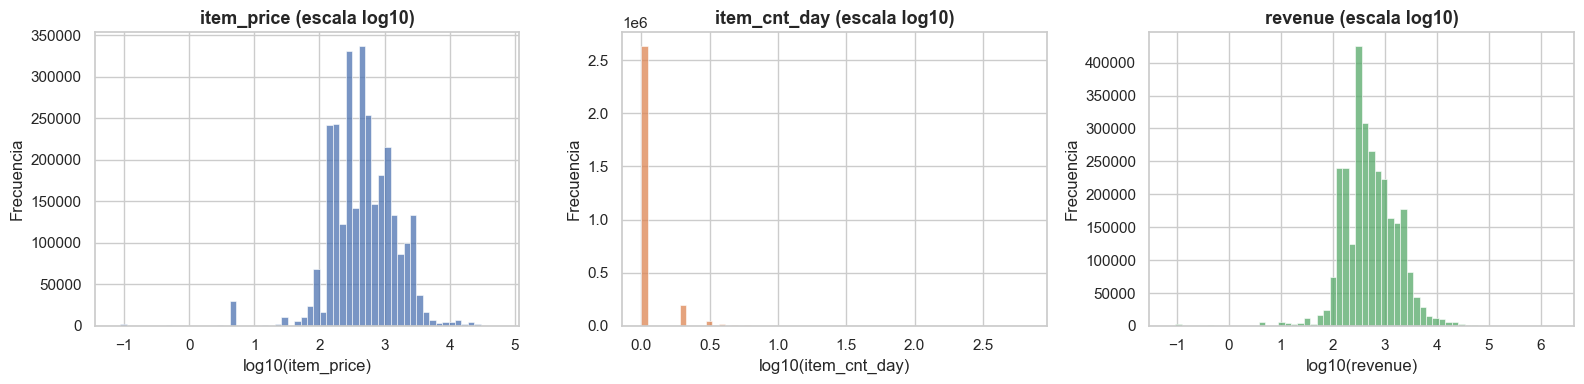

In [14]:
variables = ["item_price", "item_cnt_day", "revenue"]
resumen = df[variables].agg(["mean", "median", "min", "max", "std", "skew", "kurt"]).T
resumen.columns = ["media", "mediana", "mínimo", "máximo", "desv_estándar", "asimetría", "curtosis"]
resumen["coef_variación"] = resumen["desv_estándar"] / resumen["media"]
cuantiles = df[variables].quantile([0.25, 0.75, 0.95, 0.99]).T
cuantiles.columns = ["P25", "P75", "P95", "P99"]
display(pd.concat([resumen, cuantiles], axis=1))

print("Distribución de item_cnt_day (% de transacciones):")
print((df["item_cnt_day"].value_counts(normalize=True).head(5) * 100).round(2))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col, color in zip(axes, variables, ["#4C72B0", "#DD8452", "#55A868"]):
    datos = df.loc[df[col] > 0, col]
    sns.histplot(np.log10(datos), bins=60, ax=ax, color=color)
    ax.set_title(f"{col} (escala log10)"); ax.set_xlabel(f"log10({col})"); ax.set_ylabel("Frecuencia")
plt.tight_layout(); guardar("05a_distribucion_variables"); plt.show()

**Interpretación (5b-ii):**
- Las **57 tiendas** tienen un desempeño muy desigual: la mediana es de **53,886 unidades** en el período, con un **coeficiente de variación de 0.91**.
- La tienda líder es **Moscú CC Semenovsky (ID 31)**, con **310,777 unidades (8.5 %)**, seguida de **Moscú CCE Atrium (25)**, **Jimki CC Mega (54)** y **Moscú CC MEGA Teply Stan II (28)**. Las **5 principales concentran el 29.5 %** de las unidades.
- **Moscú** concentra el **35 %** de las unidades de toda la cadena.
- No todas las tiendas operaron los 34 meses: algunas abrieron o cerraron durante el período. Por eso se compara la **venta por mes activo** y no el total acumulado. La distribución es asimétrica: la mayoría de tiendas vende entre 1,000 y 4,000 unidades al mes, y pocas superan las 6,000.
- Para el forecasting, la **tienda** es una variable relevante: el nivel base de ventas cambia mucho entre sucursales.

### 5b. Distribución de las ventas 
### i. Por producto y categoría

Productos con ventas: 21,806


,count,mean,std,min,25%,50%,75%,90%,99%,max
unidades por producto,"21,806.00",167.16,"1,359.57",-11.00,7.00,33.00,124.00,360.00,"1,991.80","186,642.00"


El 17.8 % de los productos concentra el 80 % de las unidades vendidas
Índice de Gini de las ventas por producto: 0.793


,unidades,ingresos,% unidades,% ingresos
categoria_grupo,,,,
Cine,"916,941.00","334,987,320.19",25.16,9.86
Juegos PC,"689,098.00","477,981,687.75",18.91,14.06
Juegos consola,"646,770.00","1,153,844,546.55",17.74,33.95
Regalos,"583,366.00","309,142,571.48",16.00,9.10
Música,"411,294.00","149,719,998.79",11.28,4.41
Accesorios,"85,056.00","166,386,781.45",2.33,4.90
Libros,"76,341.00","30,348,897.24",2.09,0.89
Software,"74,953.00","122,082,915.13",2.06,3.59
Tarjetas de pago,"53,883.00","72,953,095.72",1.48,2.15


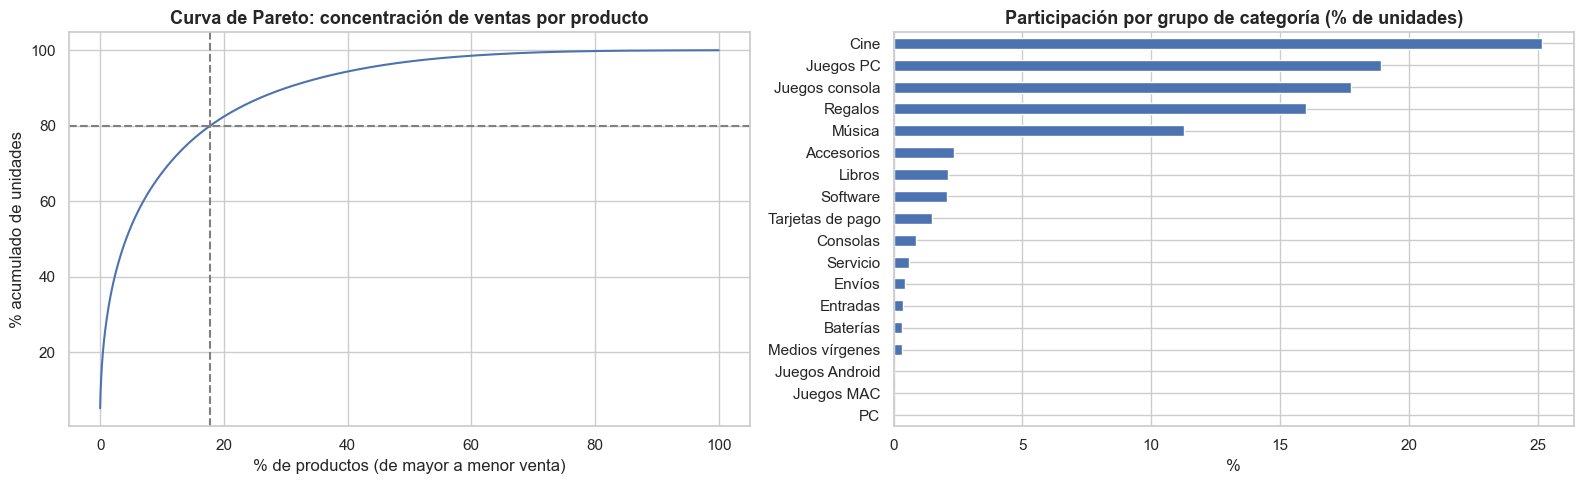

In [15]:
prod = (df.groupby(["item_id", "item_name", "categoria_nombre"])
          .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"),
               transacciones=("item_cnt_day", "size"))
          .reset_index().sort_values("unidades", ascending=False))
print(f"Productos con ventas: {len(prod):,}")
display(prod["unidades"].describe(percentiles=[0.25, 0.5, 0.75, 0.9, 0.99]).to_frame("unidades por producto").T)

acum = prod["unidades"].cumsum() / prod["unidades"].sum()
pct_prod_80 = (acum <= 0.80).sum() / len(prod) * 100
def gini(x):
    x = np.sort(np.asarray(x, dtype=float)); x = x[x > 0]; n = len(x)
    return (2 * np.sum(np.arange(1, n + 1) * x) / (n * x.sum())) - (n + 1) / n
print(f"El {pct_prod_80:.1f} % de los productos concentra el 80 % de las unidades vendidas")
print(f"Índice de Gini de las ventas por producto: {gini(prod['unidades']):.3f}")

cat = (df.groupby(["categoria_grupo", "categoria_nombre"])
         .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"), productos=("item_id", "nunique"))
         .reset_index())
cat["% unidades"] = cat["unidades"] / cat["unidades"].sum() * 100
cat["% ingresos"] = cat["ingresos"] / cat["ingresos"].sum() * 100
grupo = (cat.groupby("categoria_grupo")[["unidades", "ingresos", "% unidades", "% ingresos"]]
            .sum().sort_values("unidades", ascending=False))
display(grupo)

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
axes[0].plot(np.arange(1, len(prod) + 1) / len(prod) * 100, acum.values * 100, color="#4C72B0")
axes[0].axhline(80, ls="--", color="gray"); axes[0].axvline(pct_prod_80, ls="--", color="gray")
axes[0].set_title("Curva de Pareto: concentración de ventas por producto")
axes[0].set_xlabel("% de productos (de mayor a menor venta)"); axes[0].set_ylabel("% acumulado de unidades")
grupo["% unidades"].sort_values().plot.barh(ax=axes[1], color="#4C72B0")
axes[1].set_title("Participación por grupo de categoría (% de unidades)"); axes[1].set_xlabel("%"); axes[1].set_ylabel("")
plt.tight_layout(); guardar("05b_productos_categorias"); plt.show()

####  ii. Por sucursal (tienda)

,count,mean,std,min,25%,50%,75%,max
unidades por tienda,57.00,"63,947.89","58,411.18",330.00,"25,838.00","53,886.00","70,308.00","310,777.00"


Coeficiente de variación entre tiendas: 0.91
Las 5 tiendas principales concentran el 29.5 % de las unidades


,shop_id,tienda_nombre,ciudad,tienda_tipo,unidades,ingresos,productos,meses_activos,unidades_por_mes,% unidades
28,31,Moscú CC Semenovsky,Moscú,Física,"310,777.00","235,217,019.05",14416,34,"9,140.50",8.53
22,25,Moscú CCE Atrium,Moscú,Física,"241,919.00","216,479,572.44",15367,34,"7,115.26",6.64
51,54,Jimki CC Mega,Jimki,Física,"185,789.00","141,939,524.00",13863,28,"6,635.32",5.10
25,28,Moscú CC MEGA Teply Stan II,Moscú,Física,"184,557.00","159,746,337.38",12572,34,"5,428.15",5.06
54,57,Yakutsk Ordzhonikidze 56,Yakutsk,Física,"152,812.00","119,637,153.53",12815,34,"4,494.47",4.19
39,42,San Petersburgo CC Nevsky Tsentr,San Petersburgo,Física,"144,933.00","151,916,533.55",12034,34,"4,262.74",3.98
24,27,Moscú CC MEGA Belaya Dacha II,Moscú,Física,"136,657.00","140,632,474.12",10842,32,"4,270.53",3.75
4,6,Voronezh (Plekhanovskaya 13),Voronezh,Física,"100,489.00","98,067,453.80",11856,34,"2,955.56",2.76
55,58,Yakutsk CC Tsentralny,Yakutsk,Física,"88,045.00","71,975,824.83",9086,34,"2,589.56",2.42
43,46,Sergiev Posad CC 7Ya,Sergiev Posad,Física,"78,990.00","74,189,318.92",9149,34,"2,323.24",2.17



Participación por ciudad (% de unidades):
ciudad
Moscú             35.02
Yakutsk            6.61
San Petersburgo    5.36
Jimki              5.10
Voronezh           4.70
Name: item_cnt_day, dtype: float64


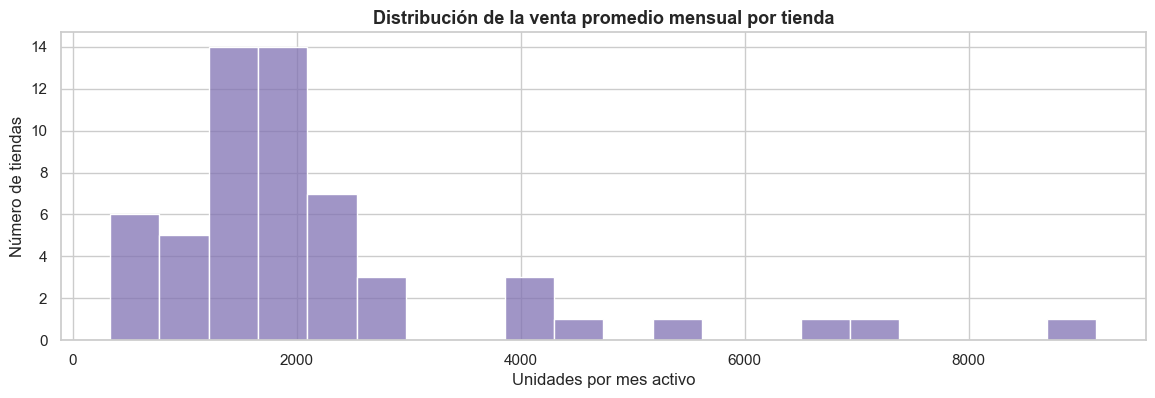

In [16]:
tienda = (df.groupby(["shop_id", "tienda_nombre", "ciudad", "tienda_tipo"])
            .agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"),
                 productos=("item_id", "nunique"), meses_activos=("date_block_num", "nunique"))
            .reset_index().sort_values("unidades", ascending=False))
tienda["unidades_por_mes"] = tienda["unidades"] / tienda["meses_activos"]
tienda["% unidades"] = tienda["unidades"] / tienda["unidades"].sum() * 100

display(tienda["unidades"].describe().to_frame("unidades por tienda").T)
print(f"Coeficiente de variación entre tiendas: {tienda['unidades'].std() / tienda['unidades'].mean():.2f}")
print(f"Las 5 tiendas principales concentran el {tienda['% unidades'].head(5).sum():.1f} % de las unidades")
display(tienda.head(10))

ciudad = df.groupby("ciudad")["item_cnt_day"].sum().sort_values(ascending=False)
print("\nParticipación por ciudad (% de unidades):")
print((ciudad / ciudad.sum() * 100).head(5).round(2))

fig, ax = plt.subplots(figsize=(14, 4))
sns.histplot(tienda["unidades_por_mes"], bins=20, ax=ax, color="#8172B3")
ax.set_title("Distribución de la venta promedio mensual por tienda")
ax.set_xlabel("Unidades por mes activo"); ax.set_ylabel("Número de tiendas")
guardar("05b_tiendas_distribucion"); plt.show()

**Interpretación (5b-ii):**
- Las **57 tiendas** tienen un desempeño muy desigual: la mediana es de **53,886 unidades** en todo el período, con un **coeficiente de variación de 0.91**. La dispersión entre tiendas es casi del mismo tamaño que su promedio.
- La tienda líder es **Moscú CC Semenovsky (ID 31)**, con **310,777 unidades (8.5 %)** y ~9,140 unidades por mes. Le siguen **Moscú CCE Atrium (25)**, **Jimki CC Mega (54)**, **Moscú CC MEGA Teply Stan II (28)** y **Yakutsk Ordzhonikidze 56 (57)**. Estas **5 tiendas concentran el 29.5 %** de las unidades.
- **Por ciudad**, **Moscú concentra el 35 %** de las unidades de toda la cadena, seguida de lejos por Yakutsk (6.6 %), San Petersburgo (5.4 %), Jimki (5.1 %) y Voronezh (4.7 %).
- **Histograma:** la distribución es **asimétrica a la derecha**. La mayoría de las tiendas (~35 de 57) vende **entre 1,200 y 2,500 unidades por mes activo**; unas 11 venden menos de 1,200; y solo un grupo pequeño (~8 tiendas) supera las 4,000. Las grandes son casi todas centros comerciales de Moscú y alrededores.
- No todas las tiendas operaron los 34 meses (por ejemplo, Jimki operó 28 y Belaya Dacha 32). Por eso se compara la **venta por mes activo** y no el total acumulado.
- **Para el forecasting:** la **tienda** es una variable relevante, porque el nivel base de ventas cambia mucho entre sucursales. Un modelo único para todas tendría que capturar ese efecto de nivel.

#### iii. Por período de tiempo (día, semana, mes, año)

,count,mean,std,min,25%,50%,75%,max,coef_variación
Diaria,"1,034.00","3,525.17","1,586.37","1,274.00","2,457.50","3,143.00","4,257.00","13,343.00",0.45
Semanal,146.00,"24,639.11","7,803.50","12,389.00","19,959.25","24,500.50","27,672.50","57,680.00",0.32
Mensual,34.00,"107,206.76","28,538.43","63,187.00","85,968.25","107,306.00","125,358.50","183,341.00",0.27


,unidades,ingresos,meses,unidades_por_mes,ingresos_por_mes,precio_medio
año,,,,,,
2013,"1,562,731.00","1,217,218,479.98",12,"130,227.58","101,434,873.33",726.56
2014,"1,320,884.00","1,346,773,983.81",12,"110,073.67","112,231,165.32",988.34
2015,"761,415.00","834,617,160.78",10,"76,141.50","83,461,716.08","1,062.33"


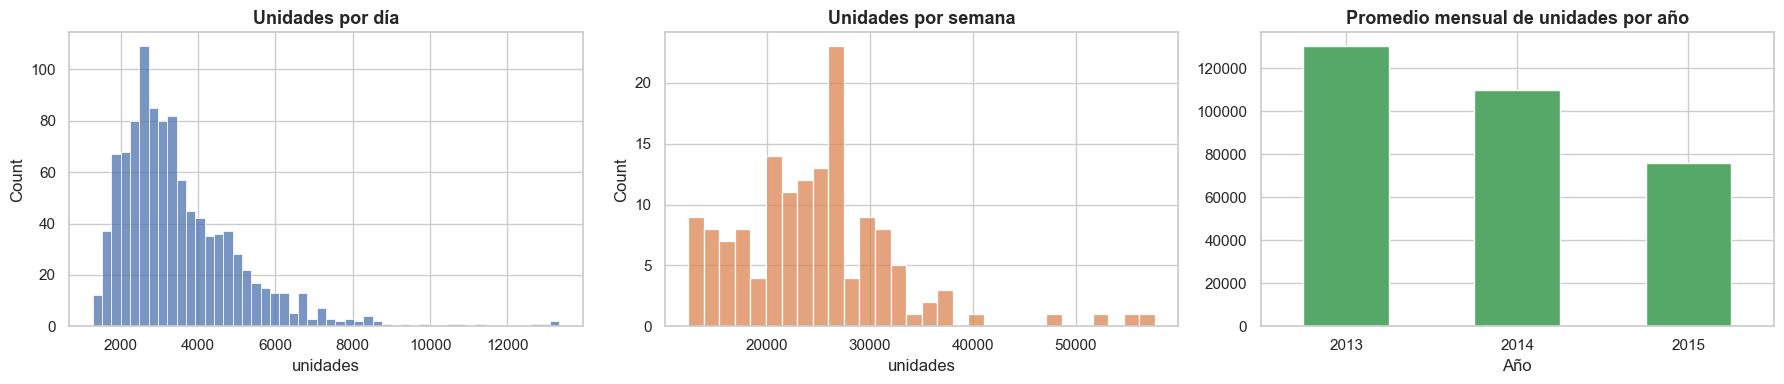

In [17]:
# Variables de calendario (se reutilizan en la sección 6)
df["año"] = df["date"].dt.year
df["mes"] = df["date"].dt.month
df["semana"] = df["date"].dt.to_period("W-SUN").dt.start_time
df["dia_semana"] = df["date"].dt.dayofweek   # 0 = lunes ... 6 = domingo

diaria = df.groupby("date").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
semanal = (df.groupby("semana").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
             .iloc[1:-1])   # se quitan la primera y la última semana porque están incompletas
mensual = df.groupby("date_block_num").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"))
mensual.index = pd.date_range("2013-01-01", periods=34, freq="MS")

anual = df.groupby("año").agg(unidades=("item_cnt_day", "sum"), ingresos=("revenue", "sum"),
                              meses=("date_block_num", "nunique"))
anual["unidades_por_mes"] = anual["unidades"] / anual["meses"]
anual["ingresos_por_mes"] = anual["ingresos"] / anual["meses"]
anual["precio_medio"] = df.groupby("año")["item_price"].mean()

estad = pd.DataFrame({"Diaria": diaria["unidades"].describe(),
                      "Semanal": semanal["unidades"].describe(),
                      "Mensual": mensual["unidades"].describe()}).T
estad["coef_variación"] = estad["std"] / estad["mean"]
display(estad)
display(anual)

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
sns.histplot(diaria["unidades"], bins=50, ax=axes[0], color="#4C72B0"); axes[0].set_title("Unidades por día")
sns.histplot(semanal["unidades"], bins=30, ax=axes[1], color="#DD8452"); axes[1].set_title("Unidades por semana")
anual["unidades_por_mes"].plot.bar(ax=axes[2], color="#55A868")
axes[2].set_title("Promedio mensual de unidades por año"); axes[2].set_xlabel("Año"); axes[2].tick_params(axis="x", rotation=0)
plt.tight_layout(); guardar("05b_distribucion_periodos"); plt.show()

**Interpretación (5b-iii):**
- **Diaria:** en promedio se venden **3,525 unidades por día**, entre 1,274 y 13,343. Es la frecuencia más ruidosa (**CV = 0.45**).
- **Semanal:** promedio de **24,639 unidades** (CV = 0.32).
- **Mensual:** promedio de **107,207 unidades**, entre 63,187 y 183,341. Es la frecuencia más estable (**CV = 0.27**), lo que confirma que agregar a nivel mensual reduce el ruido.
- **Anual:** el promedio mensual de unidades **cae de forma sostenida**: **130,228 (2013) → 110,074 (2014) → 76,142 (2015)**, una caída de ~42 % en dos años. En cambio, el **precio medio sube**: **727 → 988 → 1,062 rublos**. Por eso el **ingreso mensual cae mucho menos** que las unidades e incluso sube en 2014. Coincide con la devaluación del rublo de finales de 2014 y con un posible desplazamiento hacia ventas digitales.
- **Implicación para el forecasting:** la serie tiene una **tendencia decreciente** clara en unidades. El modelo no puede asumir un nivel constante: necesita un componente de tendencia o trabajar con la serie diferenciada.

## 6. Exploración temporal
### 6a. Evolución de las ventas a lo largo del tiempo

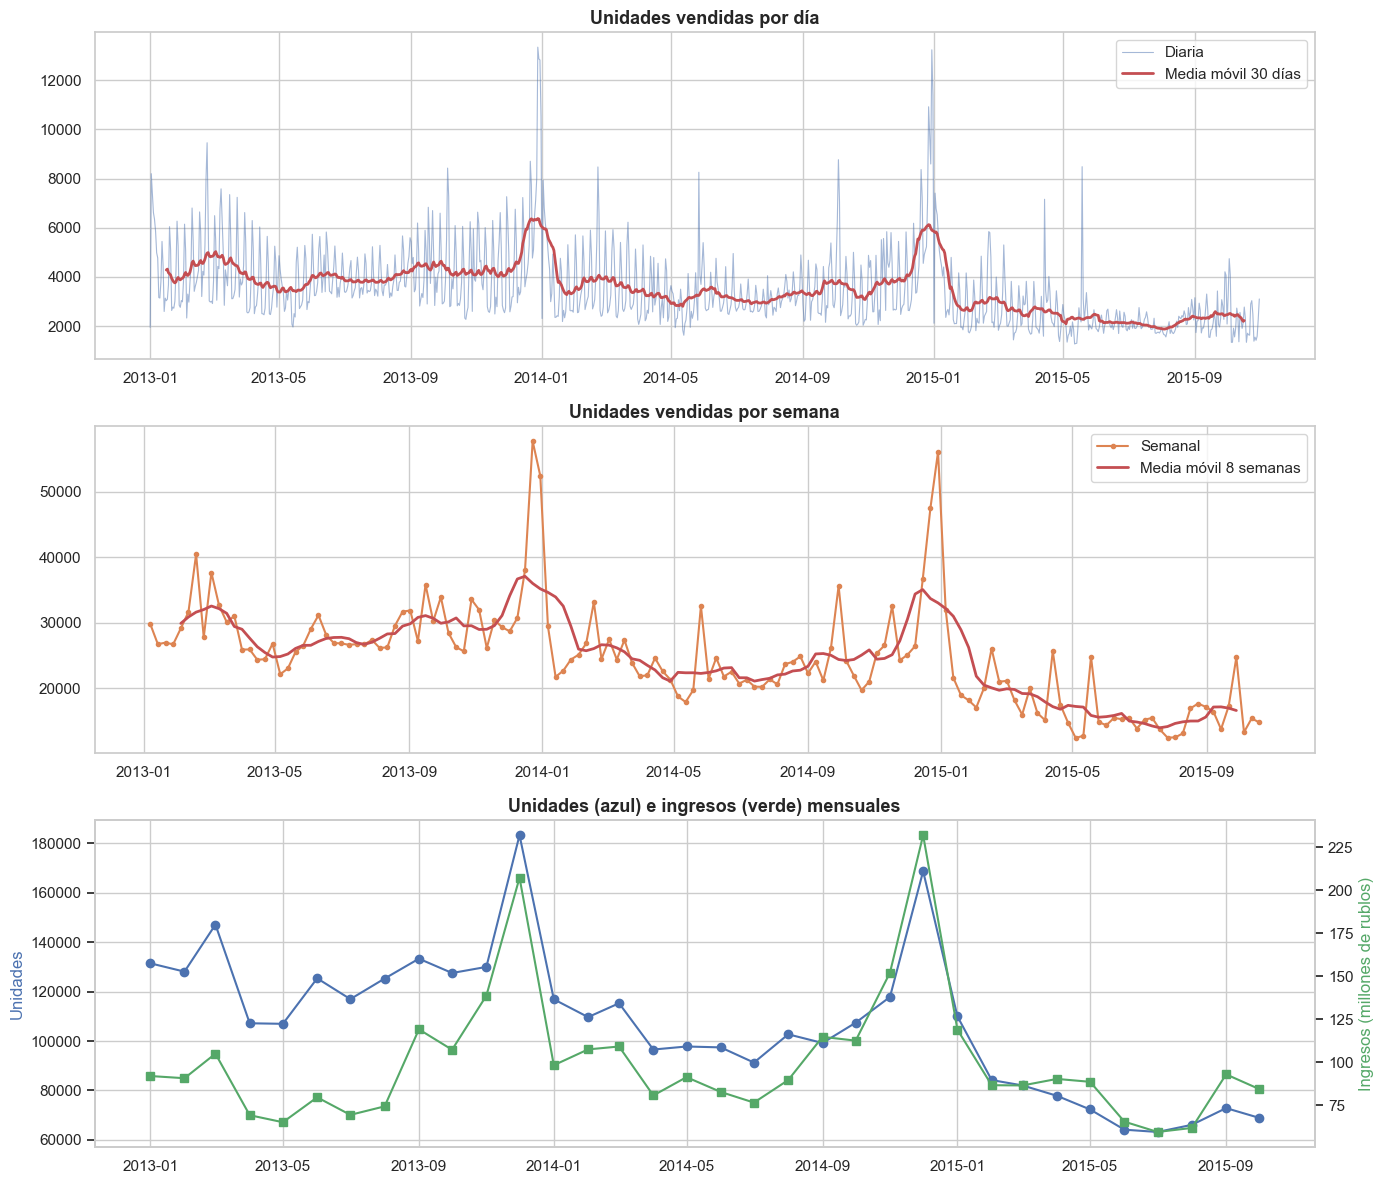

Correlación unidades vs ingresos mensuales: 0.715


In [18]:
fig, axes = plt.subplots(3, 1, figsize=(14, 12))
axes[0].plot(diaria.index, diaria["unidades"], color="#4C72B0", alpha=0.5, lw=0.8, label="Diaria")
axes[0].plot(diaria.index, diaria["unidades"].rolling(30, center=True).mean(), color="#C44E52", lw=2, label="Media móvil 30 días")
axes[0].set_title("Unidades vendidas por día"); axes[0].legend()

axes[1].plot(semanal.index, semanal["unidades"], color="#DD8452", marker=".", label="Semanal")
axes[1].plot(semanal.index, semanal["unidades"].rolling(8, center=True).mean(), color="#C44E52", lw=2, label="Media móvil 8 semanas")
axes[1].set_title("Unidades vendidas por semana"); axes[1].legend()

ax2 = axes[2].twinx()
axes[2].plot(mensual.index, mensual["unidades"], color="#4C72B0", marker="o", label="Unidades")
ax2.plot(mensual.index, mensual["ingresos"] / 1e6, color="#55A868", marker="s", label="Ingresos (millones)")
axes[2].set_title("Unidades (azul) e ingresos (verde) mensuales")
axes[2].set_ylabel("Unidades", color="#4C72B0"); ax2.set_ylabel("Ingresos (millones de rublos)", color="#55A868"); ax2.grid(False)
plt.tight_layout(); guardar("06a_evolucion_ventas"); plt.show()

print(f"Correlación unidades vs ingresos mensuales: {mensual['unidades'].corr(mensual['ingresos']):.3f}")

**Interpretación (6a):** en las tres frecuencias se ve el mismo patrón: un **nivel que baja con los años** y **dos picos muy marcados cada diciembre** (2013 y 2014). La serie diaria es muy ruidosa; la media móvil de 30 días revela la tendencia de fondo. Unidades e ingresos mensuales están correlacionados (**r = 0.72**), pero no son iguales: desde mediados de 2014 los ingresos se mantienen o suben mientras las unidades caen, porque cada producto se vende más caro. Para el forecasting de `item_cnt_month` importa la serie de **unidades**.

### 6b. Identificación de patrones
#### i. Tendencia — descomposición STL y prueba de Mann-Kendall

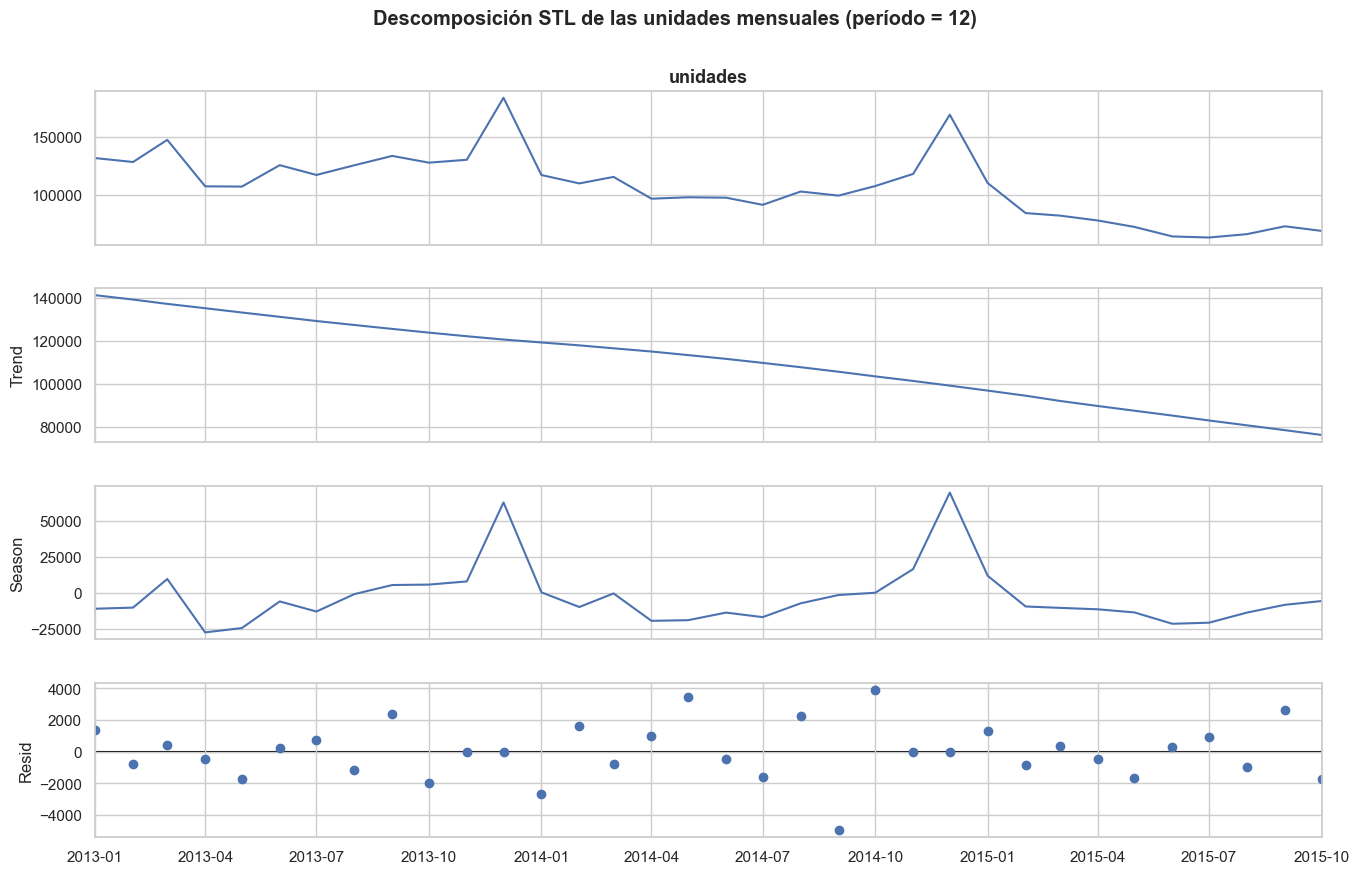

Fuerza de la tendencia:      0.99
Fuerza de la estacionalidad: 0.99
Mann-Kendall: tau = -0.579, p-valor = 1.45e-06
Pendiente de Theil-Sen: -2,067 unidades por mes
Variación interanual promedio 2014 vs 2013: -15.5 %
Variación interanual promedio 2015 vs 2014: -26.7 %


In [19]:
# stl = STL(mensual["unidades"], period=12, robust=True).fit()
stl = STL(mensual["unidades"], period=12, seasonal=13, trend=13, robust=False).fit()
fig = stl.plot(); fig.set_size_inches(14, 9)
fig.suptitle("Descomposición STL de las unidades mensuales (período = 12)", y=1.01, fontweight="bold")
guardar("06b_stl"); plt.show()

# Fuerza de cada componente (Hyndman): 0 = no existe, 1 = muy fuerte
fuerza_tend = max(0, 1 - stl.resid.var() / (stl.trend + stl.resid).var())
fuerza_est = max(0, 1 - stl.resid.var() / (stl.seasonal + stl.resid).var())
print(f"Fuerza de la tendencia:      {fuerza_tend:.2f}")
print(f"Fuerza de la estacionalidad: {fuerza_est:.2f}")

# Prueba no paramétrica de tendencia (Mann-Kendall) + pendiente de Theil-Sen
tau, p_tau = stats.kendalltau(np.arange(len(mensual)), mensual["unidades"])
pend = stats.theilslopes(mensual["unidades"], np.arange(len(mensual)))
print(f"Mann-Kendall: tau = {tau:.3f}, p-valor = {p_tau:.2e}")
print(f"Pendiente de Theil-Sen: {pend.slope:,.0f} unidades por mes")

yoy = mensual["unidades"].pct_change(12) * 100
print(f"Variación interanual promedio 2014 vs 2013: {yoy['2014'].mean():.1f} %")
print(f"Variación interanual promedio 2015 vs 2014: {yoy['2015'].mean():.1f} %")

**Interpretación (6b-i):**
- La **descomposición STL** (ventanas estacional y de tendencia de 13 meses) separa la serie mensual en tendencia, estacionalidad y residuo. La **tendencia es decreciente y se acelera ligeramente**: pasa de ~141,000 unidades/mes a inicios de 2013 a ~99,000 a finales de 2014 y a ~76,000 en octubre de 2015.
- La **prueba de Mann-Kendall** confirma estadísticamente la tendencia: **tau = −0.58, p-valor ≈ 1.5×10⁻⁶ < 0.05**, así que se rechaza la hipótesis de "no hay tendencia". La **pendiente de Theil-Sen** estima una pérdida de **~2,067 unidades por mes**.
- La caída interanual promedio fue de **−15.5 % (2014 vs 2013)** y se profundizó a **−26.7 % (2015 vs 2014)**.
- La **fuerza de la tendencia y de la estacionalidad** sale muy alta (~0.98–0.99): casi toda la variación se explica por esos dos componentes. **Precaución:** con solo 34 meses, cada mes del año tiene 2 o 3 observaciones, así que estas medidas tienden a **sobreestimarse**. Se interpretan como "ambos componentes son importantes", no como un valor exacto.
- **Para el forecasting:** el modelo necesita **un componente de tendencia y uno estacional**, por ejemplo Holt-Winters con tendencia amortiguada o SARIMA con diferenciación regular y estacional.

#### ii. Estacionalidad

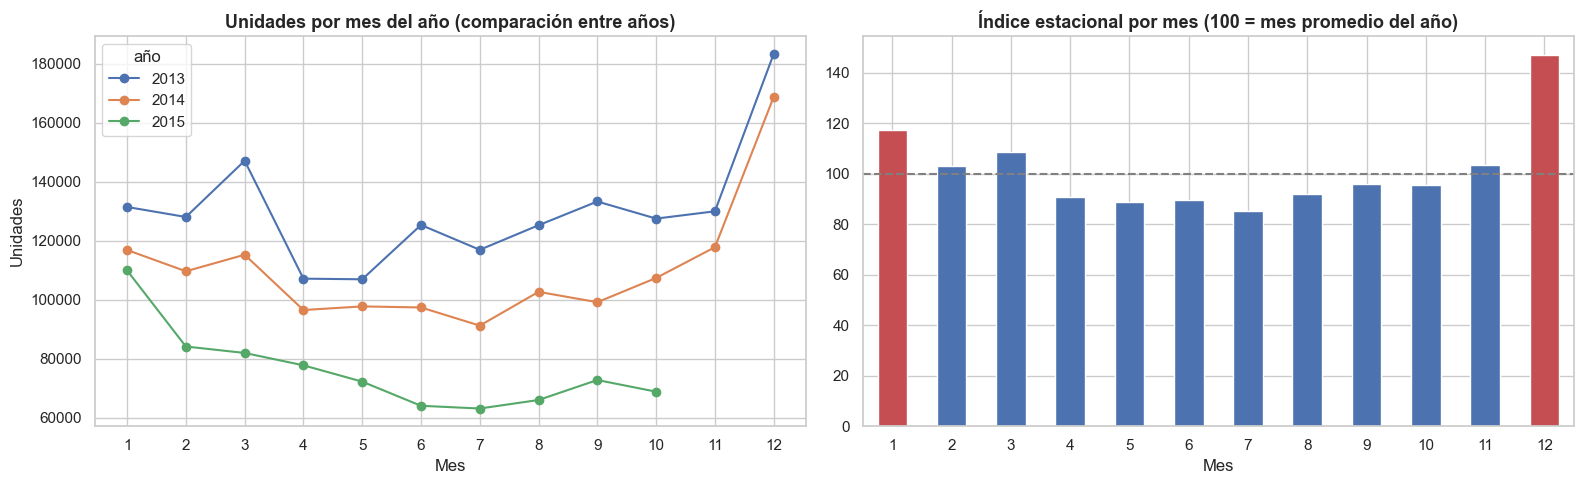

Índice estacional por mes:
mes
1    117.20
2    102.90
3    108.50
4     90.70
5     88.60
6     89.70
7     85.20
8     92.10
9     96.10
10    95.30
11   103.40
12   147.00


In [20]:
tabla = (mensual.assign(año=mensual.index.year, mes=mensual.index.month)
                .pivot(index="mes", columns="año", values="unidades"))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
tabla.plot(ax=axes[0], marker="o")
axes[0].set_title("Unidades por mes del año (comparación entre años)")
axes[0].set_xticks(range(1, 13)); axes[0].set_xlabel("Mes"); axes[0].set_ylabel("Unidades")

indice = (tabla / tabla.mean()).mean(axis=1) * 100   # cada mes respecto al promedio de su año
indice.plot.bar(ax=axes[1], color=["#C44E52" if v > 110 else "#4C72B0" for v in indice])
axes[1].axhline(100, ls="--", color="gray")
axes[1].set_title("Índice estacional por mes (100 = mes promedio del año)")
axes[1].set_xlabel("Mes"); axes[1].tick_params(axis="x", rotation=0)
plt.tight_layout(); guardar("06b_estacionalidad_mensual"); plt.show()

print("Índice estacional por mes:")
print(indice.round(1).to_string())

**Interpretación (6b-ii):** las curvas de los tres años tienen **la misma forma, solo desplazadas hacia abajo**. Eso es estacionalidad anual estable con una tendencia decreciente encima.
- **Diciembre** es el mes más fuerte: vende **47 % más** que un mes promedio (índice 147), por las compras de Año Nuevo, la principal fiesta de regalos en Rusia.
- **Enero (117)** sigue alto por las vacaciones de Año Nuevo, que duran hasta ~10 de enero. **Marzo (108.5)** y **noviembre (103)** también superan el promedio.
- **De abril a octubre** está la temporada baja (índices de 85 a 96), con el mínimo en **julio (85)**, en pleno verano.
- **Para el forecasting:** la estacionalidad tiene **período 12** y es multiplicativa o aditiva con la misma forma cada año. Noviembre 2015, el mes a predecir, normalmente está ligeramente **por encima** de octubre (índice 103 vs 95).

#### iii. Picos o caídas abruptas

Días atípicos (|z| > 3): 15


,unidades,ingresos,z,dia
date,,,,
2014-12-30,"13,236.00","17,002,645.00",6.28,Tuesday
2013-12-30,"12,823.00","14,671,056.20",5.80,Monday
2013-12-28,"13,343.00","14,626,701.00",5.78,Saturday
2013-12-29,"12,863.00","14,273,758.50",5.63,Sunday
2015-05-19,"8,483.00","19,235,743.77",4.97,Tuesday
2014-12-31,"11,393.00","15,021,005.13",4.79,Wednesday
2014-12-27,"10,919.00","15,649,897.60",4.14,Saturday
2014-05-27,"8,256.00","15,119,983.00",4.09,Tuesday
2014-10-04,"8,767.00","9,078,615.38",4.05,Saturday


2015-05-19: {'Ведьмак 3: Дикая охота [PC, русская версия]': 2005.0, 'Ведьмак 3: Дикая охота [PS4, русская версия]': 1804.0}
2014-05-27: {'Watch_Dogs. Специальное издание [PS4, русская версия]': 1426.0, 'Watch_Dogs. Специальное издание [PC, русская версия]': 1051.0}
2013-02-23: {'Crysis 3 [PC, русская версия]': 381.0, 'Игрушка-мялка "Сердитые птички" в ассортименте (1шт)': 82.0}

Mayores caídas mes a mes (%):
2014-01-01   -36.20
2015-01-01   -34.80
2013-04-01   -27.20
Mayores alzas mes a mes (%):
2014-12-01   43.20
2013-12-01   41.00
2013-06-01   17.20


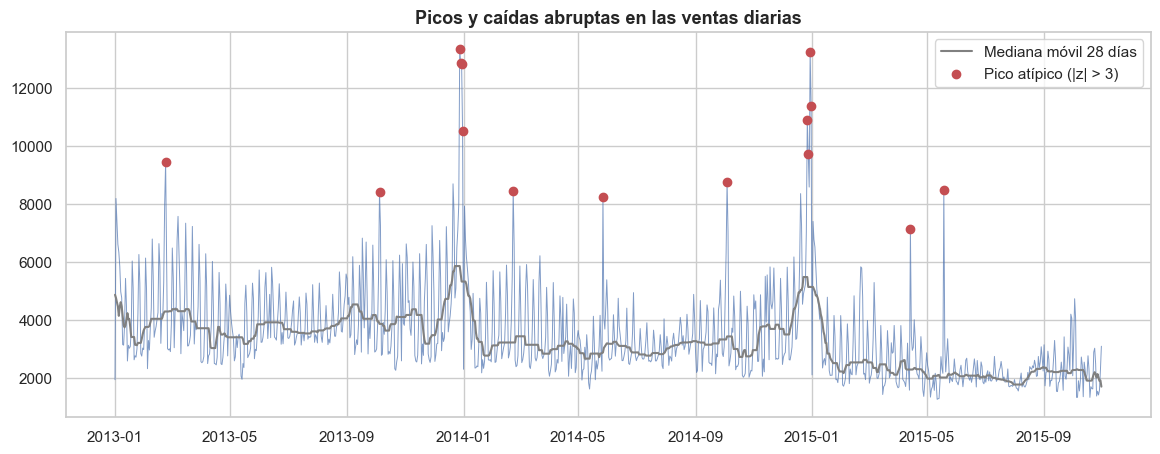

In [21]:
# Se compara cada día contra la mediana móvil de 28 días y se estandariza (z-score)
base = diaria["unidades"].rolling(28, center=True, min_periods=7).median()
desv = diaria["unidades"] - base
z = (desv - desv.mean()) / desv.std()
picos = diaria.assign(z=z, dia=diaria.index.day_name())[z.abs() > 3].sort_values("z", ascending=False)
print(f"Días atípicos (|z| > 3): {len(picos)}")
display(picos.head(12))

# ¿Qué se vendió en los picos que no son de diciembre?
for fecha in ["2015-05-19", "2014-05-27", "2013-02-23"]:
    top = df[df["date"] == fecha].groupby("item_name")["item_cnt_day"].sum().nlargest(2)
    print(f"{fecha}: {top.to_dict()}")

cambio = mensual["unidades"].pct_change() * 100
print("\nMayores caídas mes a mes (%):"); print(cambio.round(1).sort_values().head(3).to_string())
print("Mayores alzas mes a mes (%):");   print(cambio.round(1).sort_values(ascending=False).head(3).to_string())

fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(diaria.index, diaria["unidades"], color="#4C72B0", lw=0.7, alpha=0.7)
ax.plot(base.index, base, color="gray", lw=1.5, label="Mediana móvil 28 días")
ax.scatter(picos.index, picos["unidades"], color="#C44E52", zorder=3, label="Pico atípico (|z| > 3)")
ax.set_title("Picos y caídas abruptas en las ventas diarias"); ax.legend()
guardar("06b_picos"); plt.show()

**Interpretación (6b-iii):** se detectan **15 días atípicos** (|z| > 3), y todos son **picos**; no hay caídas abruptas anómalas a nivel diario. Tienen tres orígenes:
1. **Fin de año:** del **27 al 31 de diciembre** de 2013 y 2014 están los días más altos de toda la serie (>13,000 unidades vs ~3,500 de un día normal).
2. **Lanzamientos de videojuegos:** el **19-may-2015** fue el lanzamiento de *The Witcher 3* (~3,800 unidades entre PC y PS4) y el **27-may-2014** el de *Watch Dogs*. En el **23-feb-2013** se vendió fuerte *Crysis 3*, que coincide además con el feriado ruso del "Día del Defensor de la Patria".
3. **Fines de semana previos a fechas especiales** (por ejemplo, 22-feb-2014).

A nivel mensual, las **caídas abruptas** son estructurales y predecibles: **enero cae ~35 %** respecto a diciembre (2014 y 2015) y abril de 2013 cae 27 %. Las alzas más fuertes son **diciembre (+41 % y +43 %)**.

**Para el forecasting:** los lanzamientos son eventos **no estacionales** que generan picos difíciles de predecir con la sola historia. Conviene tratarlos como variables exógenas o aceptar que son error irreducible del modelo.

#### iv. Ciclos por día de la semana y por mes del año

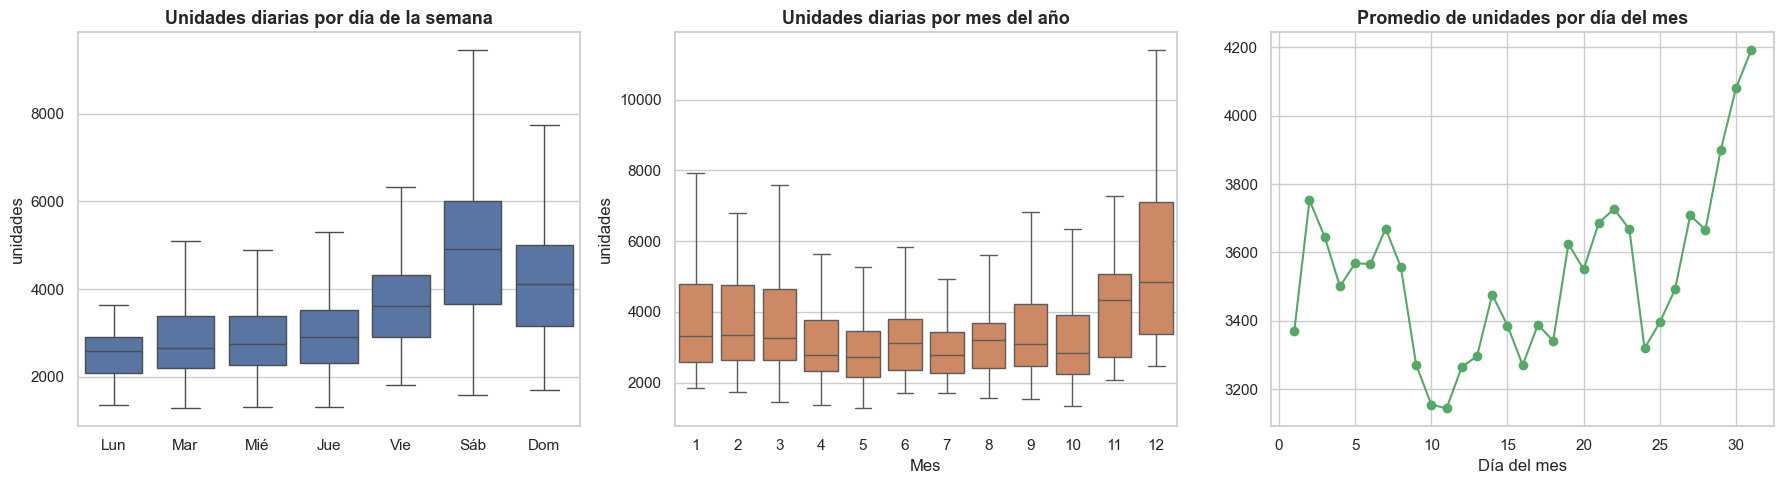

Índice por día de la semana (100 = día promedio):
Lun    77.50
Mar    87.20
Mié    83.90
Jue    87.00
Vie   106.10
Sáb   140.80
Dom   117.60

Kruskal-Wallis día de la semana: H = 278.2, p-valor = 3.74e-57
Kruskal-Wallis mes del año:      H = 113.7, p-valor = 3.34e-19
Spearman unidades mensuales vs # días de fin de semana: rho = 0.11, p-valor = 0.54


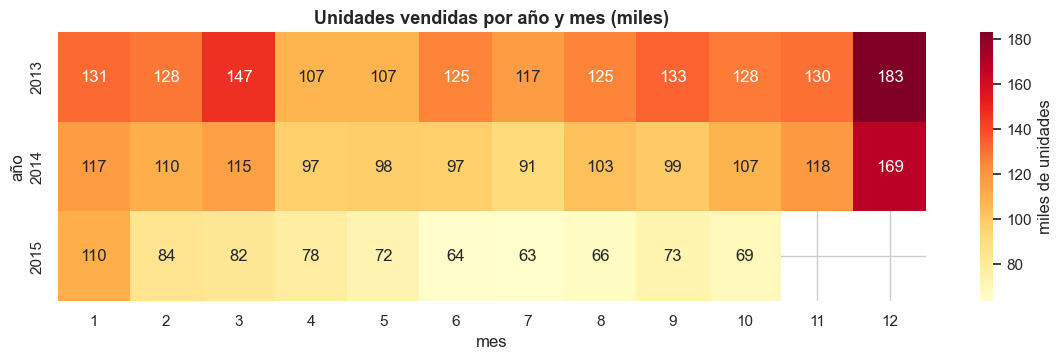

In [22]:
nombres_dia = ["Lun", "Mar", "Mié", "Jue", "Vie", "Sáb", "Dom"]
diaria_cal = diaria.assign(dia_semana=diaria.index.dayofweek, mes=diaria.index.month,
                           dia_mes=diaria.index.day, año=diaria.index.year)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
sns.boxplot(data=diaria_cal, x="dia_semana", y="unidades", ax=axes[0], color="#4C72B0", showfliers=False)
axes[0].set_xticks(range(7)); axes[0].set_xticklabels(nombres_dia)
axes[0].set_title("Unidades diarias por día de la semana"); axes[0].set_xlabel("")
sns.boxplot(data=diaria_cal, x="mes", y="unidades", ax=axes[1], color="#DD8452", showfliers=False)
axes[1].set_title("Unidades diarias por mes del año"); axes[1].set_xlabel("Mes")
diaria_cal.groupby("dia_mes")["unidades"].mean().plot(ax=axes[2], marker="o", color="#55A868")
axes[2].set_title("Promedio de unidades por día del mes"); axes[2].set_xlabel("Día del mes")
plt.tight_layout(); guardar("06b_ciclos"); plt.show()

prom_dia = diaria_cal.groupby("dia_semana")["unidades"].mean()
print("Índice por día de la semana (100 = día promedio):")
print((prom_dia / prom_dia.mean() * 100).round(1).set_axis(nombres_dia).to_string())

# Prueba de Kruskal-Wallis: ¿las ventas difieren entre grupos? (no asume normalidad)
kw_dia = stats.kruskal(*[g["unidades"] for _, g in diaria_cal.groupby("dia_semana")])
kw_mes = stats.kruskal(*[g["unidades"] for _, g in diaria_cal.groupby("mes")])
print(f"\nKruskal-Wallis día de la semana: H = {kw_dia.statistic:.1f}, p-valor = {kw_dia.pvalue:.2e}")
print(f"Kruskal-Wallis mes del año:      H = {kw_mes.statistic:.1f}, p-valor = {kw_mes.pvalue:.2e}")

# ¿Los meses con más fines de semana venden más?
calendario_fs = pd.Series(pd.date_range("2013-01-01", "2015-10-31"))
fines = calendario_fs[calendario_fs.dt.dayofweek >= 5].dt.to_period("M").value_counts().sort_index()
rho, p_rho = stats.spearmanr(mensual["unidades"].values, fines.values)
print(f"Spearman unidades mensuales vs # días de fin de semana: rho = {rho:.2f}, p-valor = {p_rho:.2f}")

heat = diaria_cal.pivot_table(index="año", columns="mes", values="unidades", aggfunc="sum")
fig, ax = plt.subplots(figsize=(14, 3.5))
sns.heatmap(heat / 1000, annot=True, fmt=".0f", cmap="YlOrRd", ax=ax, cbar_kws={"label": "miles de unidades"})
ax.set_title("Unidades vendidas por año y mes (miles)"); guardar("06b_heatmap_anio_mes"); plt.show()

**Interpretación (6b-iv):**
- **Ciclo semanal:** muy marcado. El **sábado** vende **41 % más** que un día promedio (índice 141) y el **domingo 18 % más** (118). De lunes a jueves es la parte baja de la semana, con el **lunes como el día más débil (77)**. Las tiendas están en centros comerciales, que se llenan los fines de semana.
- **Ciclo anual:** el boxplot por mes confirma diciembre como el mes con más venta diaria y el verano como el más bajo.
- **Prueba estadística:** **Kruskal-Wallis** rechaza que las ventas sean iguales entre días de la semana (**H = 278, p ≈ 10⁻⁵⁷**) y entre meses del año (**H = 114, p ≈ 10⁻¹⁹**). Ambos ciclos son **estadísticamente significativos**.
- **Día del mes:** el promedio sube mucho los días 28–31, pero ese efecto lo genera **diciembre** (compras del 27 al 31 por Año Nuevo). Al excluir diciembre, el patrón es suave: los **primeros días del mes (2 al 8) venden ~4–13 % más** que el promedio y la **mitad del mes (días 10 al 13) es la parte más baja (~7 % menos)**. Esto sugiere un leve efecto de inicio de mes, posiblemente asociado al pago de salarios, pero de magnitud mucho menor que el ciclo semanal.

- **Fines de semana por mes:** la correlación entre las unidades mensuales y la cantidad de sábados y domingos del mes **no es significativa** (rho = 0.11, p = 0.54). A nivel mensual, el efecto del ciclo semanal se diluye frente a la tendencia y a la estacionalidad anual.
- El **heatmap año × mes** resume todo: cada fila (año) es más clara que la anterior (tendencia ↓) y la columna de diciembre siempre es la más oscura (estacionalidad).

### 6c. Pruebas de estacionariedad (ADF y KPSS)
- **ADF:** H₀ = la serie tiene raíz unitaria (**no** es estacionaria). p < 0.05 → estacionaria.
- **KPSS:** H₀ = la serie **es** estacionaria. p < 0.05 → no estacionaria.

In [23]:
def pruebas(serie, nombre):
    s = serie.dropna()
    adf_p = adfuller(s, autolag="AIC")[1]
    kpss_p = kpss(s, regression="c", nlags="auto")[1]
    if adf_p < 0.05 and kpss_p > 0.05:
        concl = "Estacionaria"
    elif adf_p >= 0.05 and kpss_p <= 0.05:
        concl = "No estacionaria"
    else:
        concl = "Mixta / dudosa"
    return {"serie": nombre, "n": len(s), "ADF p-valor": adf_p, "KPSS p-valor": kpss_p, "conclusión": concl}

m, d = mensual["unidades"], diaria["unidades"]
estacionariedad = pd.DataFrame([
    pruebas(m, "Mensual original"),
    pruebas(m.diff(), "Mensual 1ª diferencia"),
    pruebas(m.diff(12), "Mensual diferencia estacional (12)"),
    pruebas(m.diff(12).diff(), "Mensual dif. estacional + 1ª dif."),
    pruebas(np.log(m).diff(), "Mensual log + 1ª diferencia"),
    pruebas(d, "Diaria original"),
    pruebas(d.diff(), "Diaria 1ª diferencia"),
    pruebas(d.diff(7), "Diaria diferencia semanal (7)"),
])
estacionariedad

,serie,n,ADF p-valor,KPSS p-valor,conclusión
0,Mensual original,34,0.15,0.02,No estacionaria
1,Mensual 1ª diferencia,33,0.00,0.08,Estacionaria
2,Mensual diferencia estacional (12),22,0.02,0.06,Estacionaria
3,Mensual dif. estacional + 1ª dif.,21,0.00,0.10,Estacionaria
4,Mensual log + 1ª diferencia,33,0.00,0.10,Estacionaria
5,Diaria original,1034,0.00,0.01,Mixta / dudosa
6,Diaria 1ª diferencia,1033,0.00,0.10,Estacionaria
7,Diaria diferencia semanal (7),1027,0.00,0.10,Estacionaria


**Interpretación (6c):**
- La **serie mensual original NO es estacionaria**: ADF p = 0.15 (no se rechaza la raíz unitaria) y KPSS p = 0.02 (se rechaza la estacionariedad). Es consistente con la tendencia decreciente y la estacionalidad.
- Con **una diferencia regular (d = 1)** la serie se vuelve estacionaria (ADF p < 0.01, KPSS p = 0.08). También con la **diferencia estacional (D = 1, s = 12)** y con la combinación de ambas.
- La **serie diaria original** da un resultado mixto: ADF dice estacionaria y KPSS no, señal de **tendencia determinística**. Con la primera diferencia o la diferencia semanal (lag 7) ambas pruebas coinciden en estacionaria.
- **Para el forecasting:** un modelo tipo **SARIMA(p, 1, q)(P, 1, Q)₁₂** es un buen candidato para la serie mensual. Con solo 34 observaciones, aplicar d = 1 y D = 1 deja apenas 21 datos útiles, así que hay que preferir modelos **parsimoniosos** (pocos parámetros) o alternativas como **Holt-Winters / ETS**. Los órdenes p y q se eligen con el ACF/PACF de la sección 9.

## 7. Análisis comparativo entre sucursales y productos
### 7a. Productos y categorías más y menos vendidos

In [24]:
# Nombres en español para el top 20 (el catálogo original está en ruso)
NOMBRES_ES = {
    20949: "Bolsa de marca 1C Interes (blanca)", 2808: "Diablo III [PC]", 3732: "Grand Theft Auto V [PS3]",
    17717: "Recepción de pagos 1C-Online (servicio)", 5822: "Tarjeta PlayStation Store 1000 rublos",
    3734: "Grand Theft Auto V [Xbox 360]", 6675: "Consola PlayStation 4 (500 GB)", 3731: "Grand Theft Auto V [PC]",
    1855: "Battlefield 4 [PC]", 16787: "The Last of Us [PS3]", 7856: "World of Warcraft - tarjeta 60 días",
    4181: "Kaspersky Internet Security (2 equipos)", 3331: "FIFA 14 [PC]", 2445: "Crysis 3 [PC]",
    2308: "Call of Duty: Black Ops II [PC]", 4870: "Minecraft [Xbox 360]", 6738: "StarCraft II: Heart of the Swarm [PC]",
    2814: "Diablo III: Reaper of Souls [PC]", 1830: "Battlefield 3 [PC]", 6503: "Los Sims 4 [PC]",
}
top_prod = prod.head(20).copy()
top_prod["producto_es"] = top_prod["item_id"].map(NOMBRES_ES)
top_prod["% unidades"] = top_prod["unidades"] / prod["unidades"].sum() * 100
print("TOP 20 PRODUCTOS MÁS VENDIDOS")
display(top_prod[["item_id", "producto_es", "categoria_nombre", "unidades", "ingresos", "% unidades"]])

print("PRODUCTOS MENOS VENDIDOS")
print(f"Productos con venta neta <= 1 unidad en todo el período: {(prod['unidades'] <= 1).sum():,} ({(prod['unidades'] <= 1).mean()*100:.1f} %)")
print(f"Productos con venta neta <= 0 (devoluciones >= ventas): {(prod['unidades'] <= 0).sum()}")
print(f"Productos del catálogo sin ninguna venta en el train: {items['item_id'].nunique() - prod['item_id'].nunique():,}")

cat_orden = cat.sort_values("unidades", ascending=False)
print("\nTOP 10 CATEGORÍAS")
display(cat_orden.head(10)[["categoria_nombre", "unidades", "% unidades", "ingresos", "% ingresos"]])
print("10 CATEGORÍAS MENOS VENDIDAS")
display(cat_orden.tail(10)[["categoria_nombre", "unidades", "% unidades", "ingresos", "% ingresos"]])

TOP 20 PRODUCTOS MÁS VENDIDOS


,item_id,producto_es,categoria_nombre,unidades,ingresos,% unidades
20601,20949,Bolsa de marca 1C Interes (blanca),"Regalos - Bolsos, álbumes, mousepads","186,642.00","924,863.70",5.12
2749,2808,Diablo III [PC],Juegos PC - Ediciones estándar,"17,245.00","16,852,778.42",0.47
3654,3732,Grand Theft Auto V [PS3],Juegos - PS3,"16,642.00","43,617,975.48",0.46
17417,17717,Recepción de pagos 1C-Online (servicio),Servicio (uso interno),"15,830.00","17,200,825.93",0.43
5717,5822,Tarjeta PlayStation Store 1000 rublos,Tarjetas de pago - PSN,"14,515.00","15,408,983.12",0.40
3656,3734,Grand Theft Auto V [Xbox 360],Juegos - XBOX 360,"11,688.00","31,065,160.27",0.32
6542,6675,Consola PlayStation 4 (500 GB),Consolas - PS4,"10,289.00","219,391,488.92",0.28
3653,3731,Grand Theft Auto V [PC],Juegos PC - Ediciones estándar,"10,099.00","19,983,482.89",0.28
1814,1855,Battlefield 4 [PC],Juegos PC - Ediciones estándar,"10,032.00","9,357,024.78",0.28
16492,16787,The Last of Us [PS3],Juegos - PS3,"9,227.00","21,907,839.08",0.25


PRODUCTOS MENOS VENDIDOS
Productos con venta neta <= 1 unidad en todo el período: 2,326 (10.7 %)
Productos con venta neta <= 0 (devoluciones >= ventas): 8
Productos del catálogo sin ninguna venta en el train: 364

TOP 10 CATEGORÍAS


,categoria_nombre,unidades,% unidades,ingresos,% ingresos
11,Cine - DVD,"634,170.00",17.40,"169,944,072.69",5.00
28,Juegos PC - Ediciones estándar,"456,540.00",12.52,"257,519,291.08",7.58
53,Música - CD producción local,"348,591.00",9.56,"100,022,563.57",2.94
31,Juegos - PS3,"254,887.00",6.99,"412,052,155.90",12.12
8,Cine - Blu-Ray,"203,283.00",5.58,"90,478,232.84",2.66
60,"Regalos - Bolsos, álbumes, mousepads","186,998.00",5.13,"930,206.61",0.03
26,Juegos PC - Ediciones adicionales,"174,954.00",4.80,"136,419,148.64",4.01
35,Juegos - XBOX 360,"169,940.00",4.66,"259,615,132.35",7.64
32,Juegos - PS4,"127,319.00",3.49,"373,010,312.01",10.98
65,Regalos - Juegos de mesa (compactos),"73,077.00",2.00,"24,727,890.56",0.73


10 CATEGORÍAS MENOS VENDIDAS


,categoria_nombre,unidades,% unidades,ingresos,% ingresos
30,Juegos - PS2,11.00,0.00,"3,828.20",0.00
24,Juegos MAC - Digital,8.00,0.00,"5,422.00",0.00
46,Libros - Literatura de computación,6.00,0.00,"1,654.00",0.00
58,PC - Auriculares/Headsets,3.00,0.00,263.40,0.00
49,Libros - Postales,3.00,0.00,58.00,0.00
45,Libros - Guías de viaje,3.00,0.00,300.00,0.00
44,Libros - Ficción,3.00,0.00,847.00,0.00
0,Accesorios - PS2,2.00,0.00,431.00,0.00
43,Libros - Divulgación,1.00,0.00,129.00,0.00
14,Consolas - PS2,1.00,0.00,"1,998.00",0.00


**Interpretación (7a):**
- **Producto más vendido:** la **bolsa de marca 1C Interes** (186,642 unidades, **5.1 %** de todas las unidades). No es un producto "real" sino un **artículo complementario**: se vende junto con otras compras y casi no genera ingreso (~925 mil rublos). Le siguen videojuegos de alto perfil: **Diablo III, GTA V** (en PS3, Xbox 360 y PC), **Battlefield**, **The Last of Us**, además de tarjetas de PlayStation Store.
- **La consola PS4** está en el top 20 por unidades (10,289) y es, por mucho, la que más **ingreso** genera: **219 millones de rublos**.
- **Menos vendidos:** **2,326 productos (10.7 %)** vendieron 1 unidad neta o menos en casi 3 años, **8 productos** quedaron con venta neta ≤ 0 (más devoluciones que ventas) y **364 productos** del catálogo nunca se vendieron en el train. Es la "cola larga" que se vio en la curva de Pareto.
- **Categorías:** las más vendidas son **Cine - DVD (17.4 %)**, **Juegos PC estándar (12.5 %)** y **Música - CD local (9.6 %)**. En ingresos lideran **Juegos PS3 (12.1 %)** y **PS4 (11.0 %)**. Las menos vendidas son formatos obsoletos o nichos: **PS2** (consolas, juegos y accesorios), **algunas subcategorías de libros** y **auriculares de PC**, con menos de 15 unidades cada una.

### 7b. Comparación del desempeño entre sucursales

MEJORES TIENDAS (unidades por mes activo)


,shop_id,tienda_nombre,tienda_tipo,unidades_por_mes,ticket_promedio,crec_2015_vs_2014_%,meses_activos,estado,en_test
0,31,Moscú CC Semenovsky,Física,"9,140.50",756.87,-21.47,34,Activa todo el período,True
1,25,Moscú CCE Atrium,Física,"7,115.26",894.84,-9.84,34,Activa todo el período,True
2,54,Jimki CC Mega,Física,"6,635.32",763.98,-73.86,28,Cerrada antes de oct-2015,False
3,28,Moscú CC MEGA Teply Stan II,Física,"5,428.15",865.57,-24.48,34,Activa todo el período,True
4,57,Yakutsk Ordzhonikidze 56,Física,"4,494.47",782.90,-33.44,34,Activa todo el período,True
6,27,Moscú CC MEGA Belaya Dacha II,Física,"4,270.53","1,029.09",-39.45,32,Cerrada antes de oct-2015,False
5,42,San Petersburgo CC Nevsky Tsentr,Física,"4,262.74","1,048.18",8.12,34,Activa todo el período,True
48,9,Ventas itinerantes,Itinerante,"3,966.50","1,031.94",-48.25,4,Abrió después de ene-2013,False


TIENDAS CON MENOR VOLUMEN


,shop_id,tienda_nombre,tienda_tipo,unidades_por_mes,ticket_promedio,crec_2015_vs_2014_%,meses_activos,estado,en_test
56,36,Novosibirsk CCE Galereya Novosibirsk,Física,330.00,"1,144.59",NaN,1,Abrió después de ene-2013,True
51,34,N. Nóvgorod CCE RIO,Física,403.19,"1,330.46",289.66,16,Abrió después de ene-2013,True
54,40,Rostov CCE Megatsentr Gorizont (Isla),Física,449.36,868.62,-85.04,11,Cerrada antes de oct-2015,False
53,33,Mytishchi CCE XL-3,Física,609.11,"1,085.21",75.73,9,Cerrada antes de oct-2015,False
43,10,Zhukovsky calle Chkalova 39m?,Física,738.09,794.26,-27.47,34,Activa todo el período,True
46,49,Tiumén CCE Kristall,Física,743.04,"1,178.52",6.45,23,Abrió después de ene-2013,True
47,39,Rostov CCE Megatsentr Gorizont,Física,830.85,"1,088.82",37.63,20,Abrió después de ene-2013,True
41,3,Balashikha CCE Oktyabr-Kinomir,Física,833.97,"1,062.98",-17.34,34,Activa todo el período,True


Estado de las tiendas vs presencia en test.csv:


en_test,False,True
estado,,
Abrió después de ene-2013,2,7
Activa todo el período,0,35
Cerrada antes de oct-2015,13,0


Tiendas del test que crecieron en 2015: 7 de 41
Crecimiento mediano 2015 vs 2014: -21.5 %


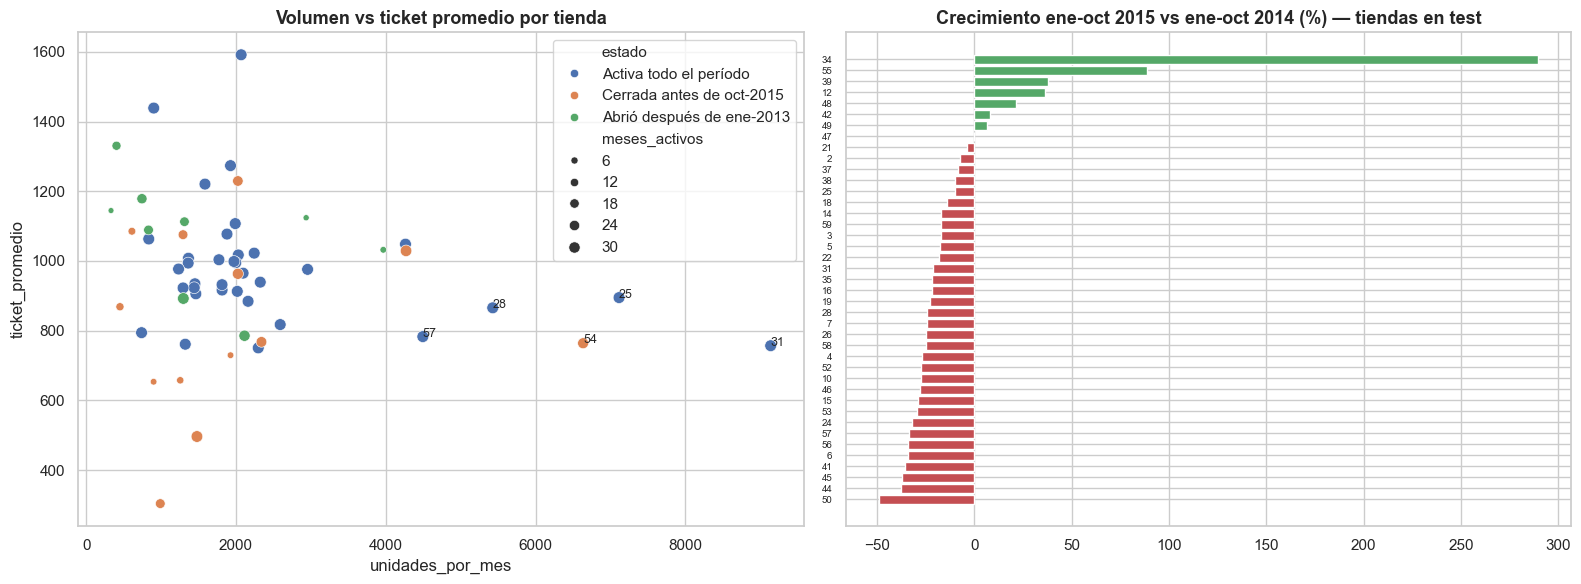

In [25]:
ventas_tm = df.groupby(["shop_id", "date_block_num"])["item_cnt_day"].sum().unstack(fill_value=0)

# Crecimiento comparando el mismo período (enero-octubre) de 2014 y 2015
ene_oct_14 = ventas_tm.loc[:, 12:21].sum(axis=1)
ene_oct_15 = ventas_tm.loc[:, 24:33].sum(axis=1)
tienda["crec_2015_vs_2014_%"] = tienda["shop_id"].map((ene_oct_15 / ene_oct_14.replace(0, np.nan) - 1) * 100)
tienda["ticket_promedio"] = tienda["ingresos"] / tienda["unidades"]

ciclo = df.groupby("shop_id")["date_block_num"].agg(primer_mes="min", ultimo_mes="max")
tienda = tienda.drop(columns=["primer_mes", "ultimo_mes"], errors="ignore").merge(ciclo, on="shop_id")
tienda["estado"] = np.select([tienda["ultimo_mes"] < 33, tienda["primer_mes"] > 0],
                             ["Cerrada antes de oct-2015", "Abrió después de ene-2013"], "Activa todo el período")
tienda["en_test"] = tienda["shop_id"].isin(test_c["shop_id"])

cols = ["shop_id", "tienda_nombre", "tienda_tipo", "unidades_por_mes", "ticket_promedio",
        "crec_2015_vs_2014_%", "meses_activos", "estado", "en_test"]
print("MEJORES TIENDAS (unidades por mes activo)")
display(tienda.sort_values("unidades_por_mes", ascending=False)[cols].head(8))
print("TIENDAS CON MENOR VOLUMEN")
display(tienda.sort_values("unidades_por_mes")[cols].head(8))
print("Estado de las tiendas vs presencia en test.csv:")
display(pd.crosstab(tienda["estado"], tienda["en_test"]))

activas = tienda[tienda["en_test"]].dropna(subset=["crec_2015_vs_2014_%"])
print(f"Tiendas del test que crecieron en 2015: {(activas['crec_2015_vs_2014_%'] > 0).sum()} de {len(activas)}")
print(f"Crecimiento mediano 2015 vs 2014: {activas['crec_2015_vs_2014_%'].median():.1f} %")

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
sns.scatterplot(data=tienda, x="unidades_por_mes", y="ticket_promedio", hue="estado", size="meses_activos", ax=axes[0])
for _, r in tienda.nlargest(5, "unidades_por_mes").iterrows():
    axes[0].annotate(r["shop_id"], (r["unidades_por_mes"], r["ticket_promedio"]), fontsize=9)
axes[0].set_title("Volumen vs ticket promedio por tienda")
g = activas.sort_values("crec_2015_vs_2014_%")
axes[1].barh(g["shop_id"].astype(str), g["crec_2015_vs_2014_%"],
             color=np.where(g["crec_2015_vs_2014_%"] > 0, "#55A868", "#C44E52"))
axes[1].set_title("Crecimiento ene-oct 2015 vs ene-oct 2014 (%) — tiendas en test")
axes[1].tick_params(axis="y", labelsize=7)
plt.tight_layout(); guardar("07b_tiendas"); plt.show()

**Interpretación (7b):**
- **Las mejores tiendas** son grandes centros comerciales de Moscú y alrededores: **Semenovsky (31)** con ~9,140 unidades/mes, **Atrium (25)** con ~7,115 y **Jimki Mega (54)** con ~6,635. Las de mayor volumen tienen un **ticket promedio más bajo** (~750–900 rublos): venden mucho producto barato (DVD, bolsas, música).
- **Ciclo de vida:** de las 57 tiendas, **35 operaron todo el período**, **9 abrieron después de enero 2013** y **13 cerraron antes de octubre 2015**. Ninguna tienda cerrada aparece en `test.csv`, así que para el forecasting **sus series históricas pueden excluirse o usarse solo como información auxiliar**. La tienda **36 (Novosibirsk)** solo tiene 1 mes de historia (oct-2015) y está en el test: es un caso de **arranque en frío**.
- **Crecimiento:** solo **7 de las 41 tiendas** del test con historia comparable crecieron en ene-oct 2015 frente a ene-oct 2014. El **crecimiento mediano es −21.5 %**. Crecen sobre todo los **canales digitales y en línea** (almacén digital 1C-Online +89 %, tienda en línea +36 %) y tiendas recién abiertas (N. Nóvgorod RIO, Rostov Gorizont). La cadena se está **desplazando de lo físico a lo digital**.
- **Para el forecasting:** la tienda determina el **nivel** de la serie y también su **dirección** (crecer o caer), así que hay que modelar cada tienda con su propio nivel o incluirla como variable.

### 7c. Detección de outliers y comportamientos anómalos

Límite superior de precio (IQR sobre log10): 8,028 rublos
Transacciones con precio atípico: 24,341 (0.83 %)
  ...de qué grupo son (%): {'Consolas': 90.7, 'Juegos consola': 3.0, 'Software': 1.9}

Percentil 99.9 de item_cnt_day: 22 unidades
Transacciones con cantidad > P99.9: 2,880
  ...de qué tienda son (%): {'Moscú CC Semenovsky': 17.4, 'Moscú CCE Atrium': 11.0, 'Tienda en línea ChS': 10.0}

Transacciones con MAYOR cantidad:


,date,shop_id,item_id,item_name,item_price,item_cnt_day
2864227,2015-09-30,12,9248,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) [...","1,692.53",669.00
2851083,2015-09-30,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...","1,702.83",637.00
2608032,2015-04-14,12,3731,"Grand Theft Auto V [PC, русские субтитры]","1,904.55",624.00
2626173,2015-05-19,12,11373,Доставка до пункта выдачи (Boxberry),155.19,539.00
2851065,2015-09-29,55,9249,"Билет ""ИгроМир 2015"" - 3 октября 2015 (сайт) У...","1,500.00",533.00
2048512,2014-10-02,12,9242,"Билет ""ИгроМир 2014"" (на один день (отдельно -...","1,500.00",512.00


Transacciones con MAYOR precio:


,date,shop_id,item_name,categoria_nombre,item_price,item_cnt_day
885137,2013-09-17,12,Доставка (EMS),Envío de productos,"59,200.00",1.00
1488132,2014-03-20,25,Коллекционные шахматы (Властелин Колец),Regalos - Souvenirs,"50,999.00",1.00
2327151,2015-01-29,12,UserGate Proxy & Firewall 6.X с модулем фильтр...,Software - Hogar y oficina,"49,782.00",1.00
2885684,2015-10-23,42,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Consolas - XBOX ONE,"42,990.00",1.00
2910147,2015-10-29,12,"Комплект ""Microsoft Xbox One 1TB Limited Edit...",Consolas - XBOX ONE,"42,990.00",1.00


Meses con venta anómala por tienda (|z| > 3):
shop_id  date_block_num
2        23               4.35
21       23               4.16
47       23               4.01
42       23               3.89
         11               3.57
39       23               3.48
21       11               3.48
38       11               3.46
dtype: float64


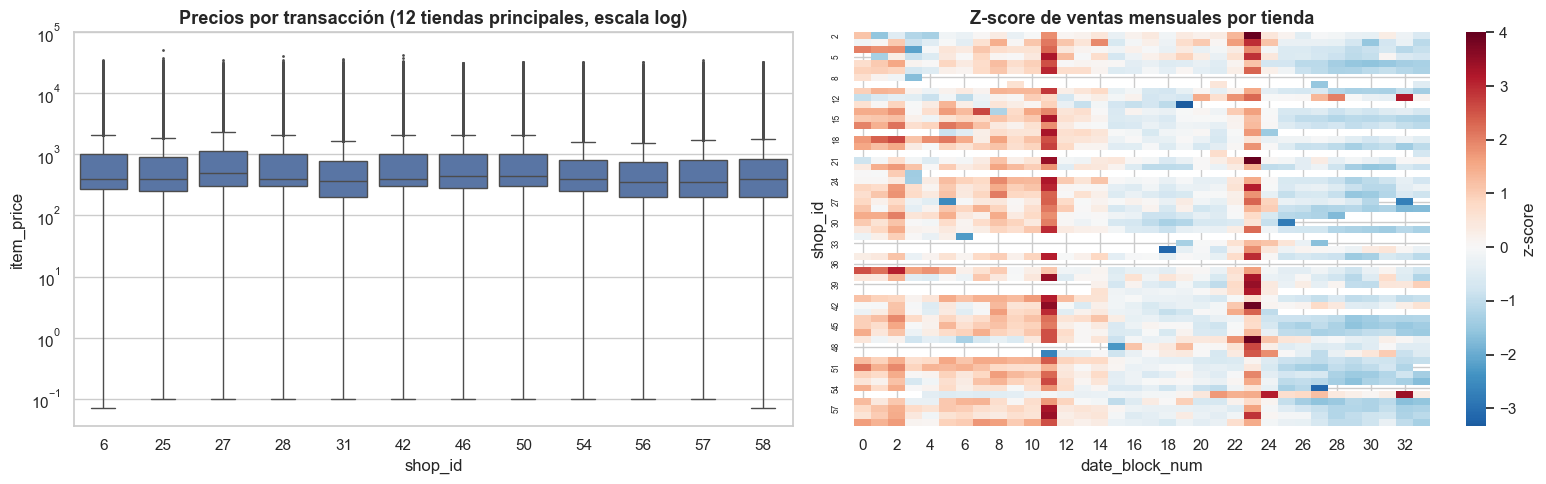

In [26]:
# Precio: IQR sobre log10 (el precio es log-normal). Cantidad: percentil 99.9
# (el IQR no sirve para la cantidad porque P25 = P75 = 1)
logp = np.log10(df["item_price"])
q1, q3 = logp.quantile([0.25, 0.75])
lim_sup_precio = 10 ** (q3 + 1.5 * (q3 - q1))
p999 = df["item_cnt_day"].quantile(0.999)

print(f"Límite superior de precio (IQR sobre log10): {lim_sup_precio:,.0f} rublos")
print(f"Transacciones con precio atípico: {(df['item_price'] > lim_sup_precio).sum():,} ({(df['item_price'] > lim_sup_precio).mean()*100:.2f} %)")
print("  ...de qué grupo son (%):", (df.loc[df["item_price"] > lim_sup_precio, "categoria_grupo"].value_counts(normalize=True).head(3) * 100).round(1).to_dict())
print(f"\nPercentil 99.9 de item_cnt_day: {p999:.0f} unidades")
print(f"Transacciones con cantidad > P99.9: {(df['item_cnt_day'] > p999).sum():,}")
print("  ...de qué tienda son (%):", (df.loc[df["item_cnt_day"] > p999, "tienda_nombre"].value_counts(normalize=True).head(3) * 100).round(1).to_dict())

print("\nTransacciones con MAYOR cantidad:")
display(df.nlargest(6, "item_cnt_day")[["date", "shop_id", "item_id", "item_name", "item_price", "item_cnt_day"]])
print("Transacciones con MAYOR precio:")
display(df.nlargest(5, "item_price")[["date", "shop_id", "item_name", "categoria_nombre", "item_price", "item_cnt_day"]])

# Meses anómalos por tienda (z-score de su propia serie mensual)
mens_t = ventas_tm.replace(0, np.nan)
z_t = mens_t.sub(mens_t.median(axis=1), axis=0).div(mens_t.std(axis=1), axis=0)
print("Meses con venta anómala por tienda (|z| > 3):")
print(z_t.stack().loc[lambda s: s.abs() > 3].sort_values(ascending=False).head(8).round(2))

fig, axes = plt.subplots(1, 2, figsize=(16, 5))
top12 = tienda.nlargest(12, "unidades")["shop_id"]
sns.boxplot(data=df[df["shop_id"].isin(top12)], x="shop_id", y="item_price", ax=axes[0], color="#4C72B0", fliersize=1)
axes[0].set_yscale("log"); axes[0].set_title("Precios por transacción (12 tiendas principales, escala log)")
sns.heatmap(z_t.clip(-4, 4), cmap="RdBu_r", center=0, ax=axes[1], cbar_kws={"label": "z-score"})
axes[1].set_title("Z-score de ventas mensuales por tienda"); axes[1].tick_params(axis="y", labelsize=6)
plt.tight_layout(); guardar("07c_outliers"); plt.show()

**Interpretación (7c):**
- **Precios atípicos:** el límite superior (IQR sobre la escala logarítmica) es de **~8,000 rublos**. Lo superan **24,341 transacciones (0.83 %)**, y el **90.7 % son consolas**. No son errores: es un segmento de precio distinto. Por eso se **conservan** y conviene analizar consolas por separado.
- **Boxplot de precios por tienda:** las 12 tiendas principales tienen una distribución de precios **muy parecida**: mediana de ~300–400 rublos y rango de 0.1 a ~40,000. Las diferencias entre tiendas vienen del **volumen**, no de los precios.
- **Cantidades atípicas:** el 99.9 % de las transacciones vende **22 unidades o menos**. Las 2,880 que superan ese umbral se concentran en **Semenovsky (17.4 %)**, **Atrium (11.0 %)** y la **tienda en línea (10.0 %)**. Las transacciones más grandes son **entradas digitales a "IgroMir"** (la feria de videojuegos de Moscú: 669 y 637 entradas en un día, septiembre 2015), la preventa de **GTA V para PC** (624) y envíos Boxberry. Son ventas de **eventos puntuales**.
- **Precios máximos:** un envío EMS de 59,200 rublos, un ajedrez de colección del Señor de los Anillos (50,999), licencias de software corporativo y una edición limitada de Xbox One (42,990). Son casos únicos, legítimos pero no representativos.
- **Meses anómalos por tienda:** todos los meses con |z| > 3 son **diciembre de 2014 (bloque 23)** o **diciembre de 2013 (bloque 11)**. El heatmap de z-scores muestra dos franjas rojas verticales en esos meses en casi todas las tiendas y un tono azul generalizado en 2015, cuando la mayoría de tiendas vende por debajo de su propio promedio (tendencia decreciente).
- **Conclusión:** salvo los 3 registros ya eliminados en la sección 4, los valores extremos son **reales** y se conservan. Para el modelo, la recomendación habitual en esta competencia es **acotar la venta mensual tienda-producto al rango [0, 20]**, que es como Kaggle evalúa el resultado.

## 8. Visualizaciones clave

### 8a · serie de tiempo de ventas totales:

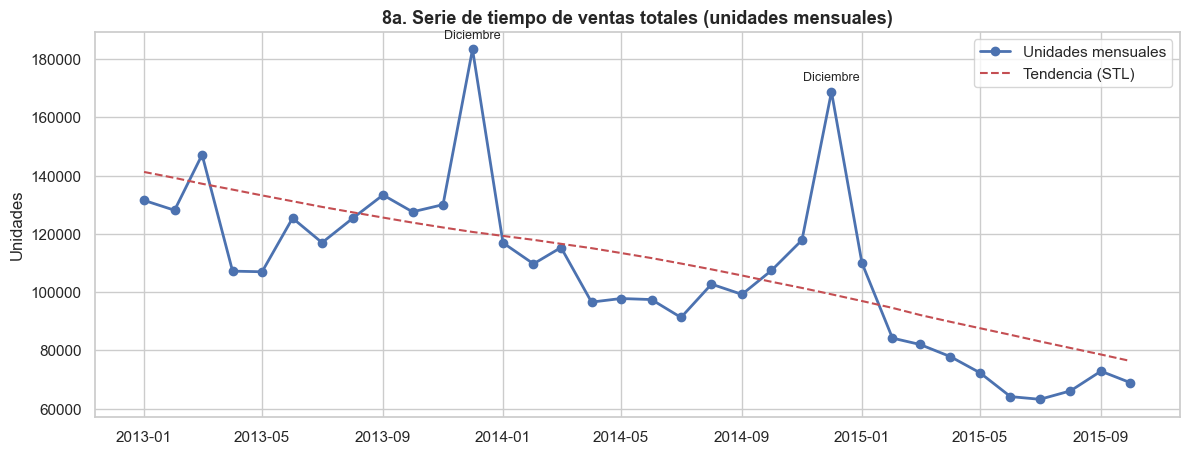

In [27]:
fig, ax = plt.subplots(figsize=(14, 5))
ax.plot(mensual.index, mensual["unidades"], marker="o", color="#4C72B0", lw=2, label="Unidades mensuales")
ax.plot(mensual.index, stl.trend, ls="--", color="#C44E52", label="Tendencia (STL)")
for fecha in mensual.index[mensual.index.month == 12]:
    ax.annotate("Diciembre", (fecha, mensual.loc[fecha, "unidades"]), textcoords="offset points", xytext=(0, 8), ha="center", fontsize=9)
ax.set_title("8a. Serie de tiempo de ventas totales (unidades mensuales)"); ax.set_ylabel("Unidades"); ax.legend()
guardar("08a_serie_ventas_totales"); plt.show()

### 8b · barras por sucursal:

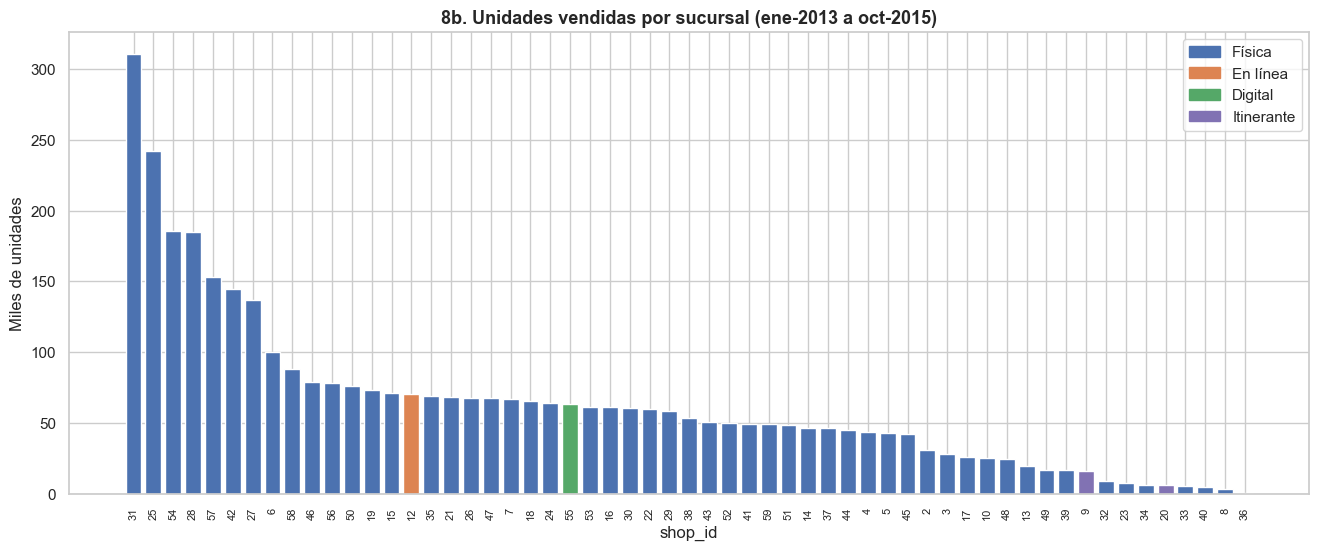

In [28]:
from matplotlib.patches import Patch
colores_tipo = {"Física": "#4C72B0", "En línea": "#DD8452", "Digital": "#55A868", "Itinerante": "#8172B3"}
orden = tienda.sort_values("unidades", ascending=False)
fig, ax = plt.subplots(figsize=(16, 6))
ax.bar(orden["shop_id"].astype(str), orden["unidades"] / 1000, color=orden["tienda_tipo"].map(colores_tipo))
ax.set_title("8b. Unidades vendidas por sucursal (ene-2013 a oct-2015)")
ax.set_xlabel("shop_id"); ax.set_ylabel("Miles de unidades"); ax.tick_params(axis="x", rotation=90, labelsize=8)
ax.legend(handles=[Patch(color=c, label=t) for t, c in colores_tipo.items()])
guardar("08b_ventas_por_sucursal"); plt.show()

### 8c · barras por producto (top 20) y por categoría

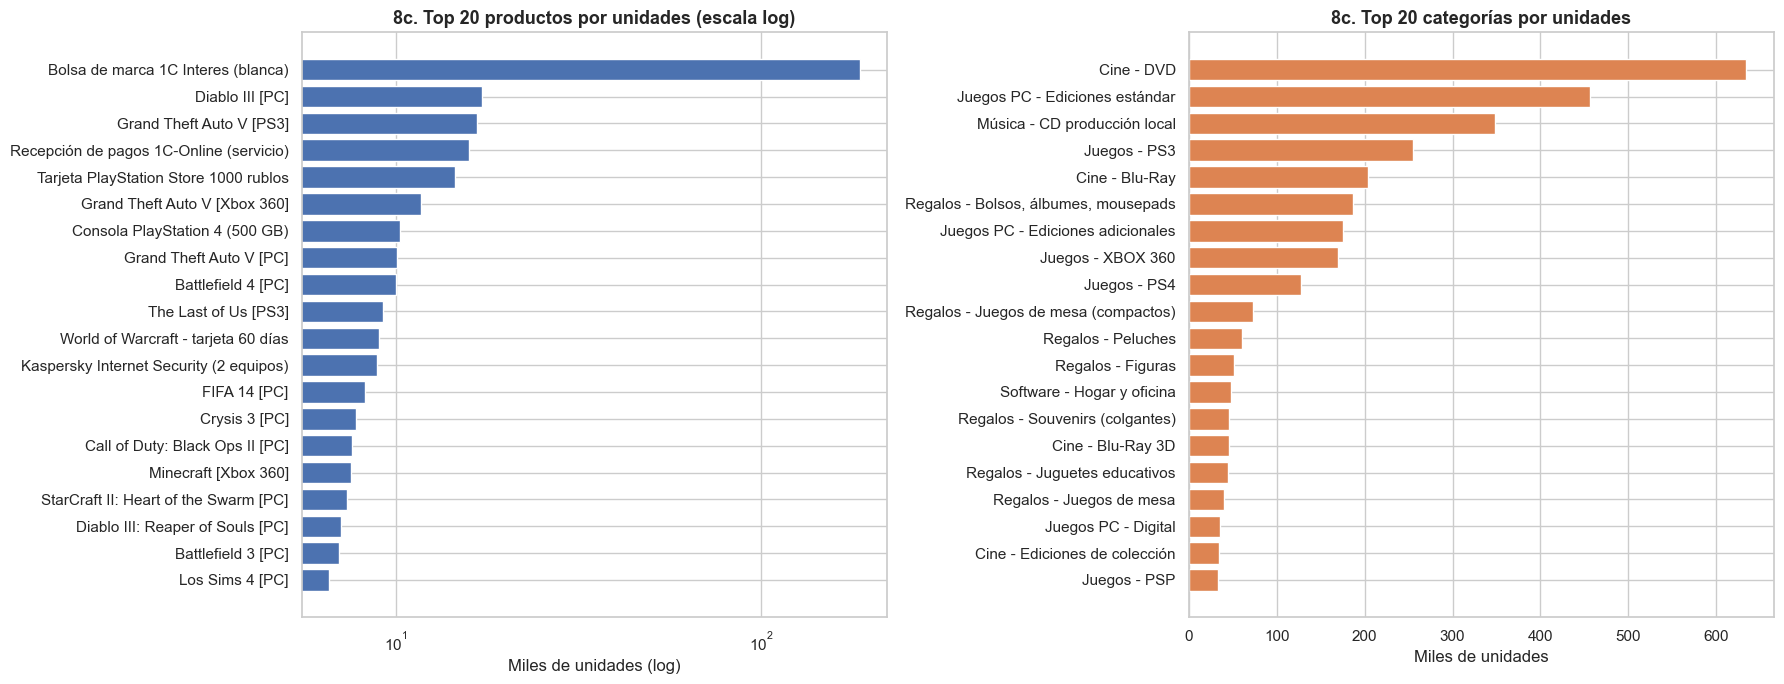

In [29]:
fig, axes = plt.subplots(1, 2, figsize=(18, 7))
tp = top_prod.sort_values("unidades")
axes[0].barh(tp["producto_es"], tp["unidades"] / 1000, color="#4C72B0")
axes[0].set_xscale("log"); axes[0].set_title("8c. Top 20 productos por unidades (escala log)"); axes[0].set_xlabel("Miles de unidades (log)")
tc = cat.nlargest(20, "unidades").sort_values("unidades")
axes[1].barh(tc["categoria_nombre"], tc["unidades"] / 1000, color="#DD8452")
axes[1].set_title("8c. Top 20 categorías por unidades"); axes[1].set_xlabel("Miles de unidades")
plt.tight_layout(); guardar("08c_ventas_por_producto_categoria"); plt.show()

### 8d.i · heatmaps en el tiempo por sucursal

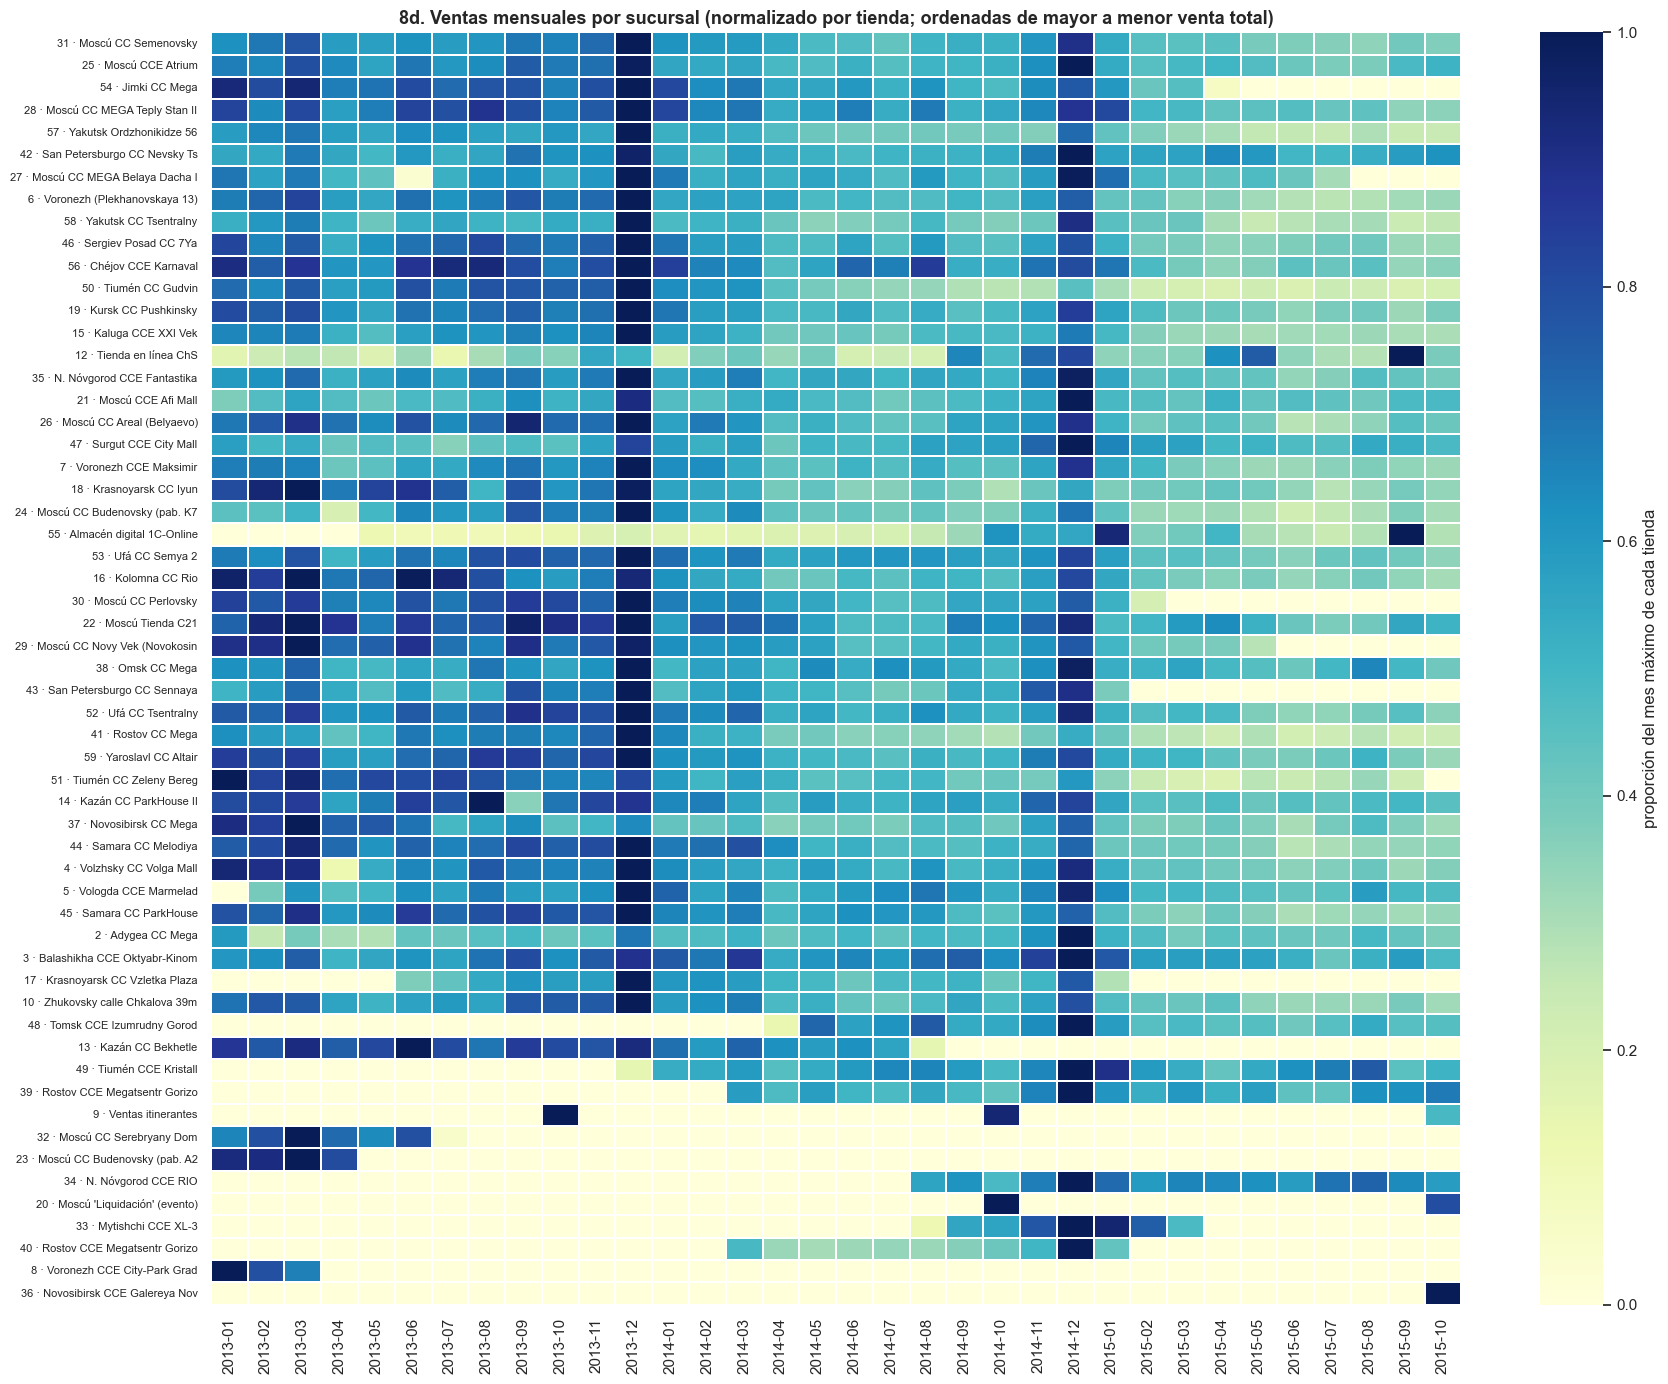

In [30]:
etiquetas_mes = [d.strftime("%Y-%m") for d in pd.date_range("2013-01", periods=34, freq="MS")]
mat_t = ventas_tm.loc[tienda.sort_values("unidades", ascending=False)["shop_id"]]
mat_t.columns = etiquetas_mes
norm_t = mat_t.div(mat_t.max(axis=1), axis=0).clip(lower=0)   # cada tienda respecto a su mejor mes
etiq = [f"{s} · {n[:28]}" for s, n in zip(mat_t.index, tienda.set_index("shop_id").loc[mat_t.index, "tienda_nombre"])]

fig, ax = plt.subplots(figsize=(18, 14))
sns.heatmap(norm_t, cmap="YlGnBu", ax=ax, linewidths=0.3, linecolor="white",
            cbar_kws={"label": "proporción del mes máximo de cada tienda"})
ax.set_yticks(np.arange(len(etiq)) + 0.5); ax.set_yticklabels(etiq, fontsize=8, rotation=0)
ax.set_title("8d. Ventas mensuales por sucursal (normalizado por tienda; ordenadas de mayor a menor venta total)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); guardar("08d_heatmap_tiendas"); plt.show()

### 8d.ii · heatmaps en el tiempo por categoría

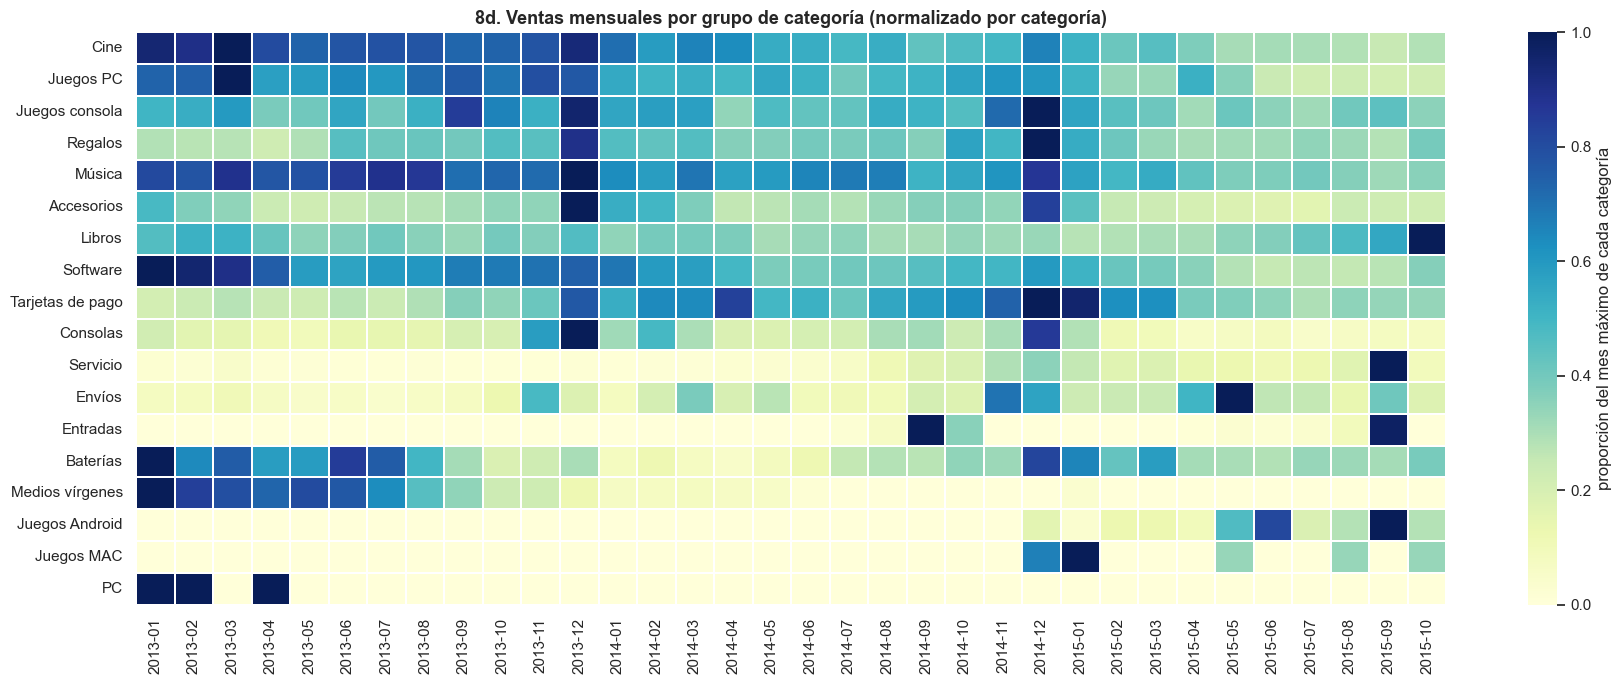

In [31]:
mat_c = df.pivot_table(index="categoria_grupo", columns="date_block_num", values="item_cnt_day", aggfunc="sum", fill_value=0)
mat_c = mat_c.loc[mat_c.sum(axis=1).sort_values(ascending=False).index]
mat_c.columns = etiquetas_mes

fig, ax = plt.subplots(figsize=(18, 7))
sns.heatmap(mat_c.div(mat_c.max(axis=1), axis=0).clip(lower=0), cmap="YlGnBu", ax=ax, linewidths=0.3, linecolor="white",
            cbar_kws={"label": "proporción del mes máximo de cada categoría"})
ax.set_title("8d. Ventas mensuales por grupo de categoría (normalizado por categoría)")
ax.set_xlabel(""); ax.set_ylabel("")
plt.tight_layout(); guardar("08d_heatmap_categorias"); plt.show()

**Interpretación (sección 8):**
- **8a. Serie total:** resume el comportamiento clave para el forecasting: **tendencia decreciente** (de ~130 mil a ~70 mil unidades/mes) con **picos de diciembre** que se repiten cada año. La serie combina tendencia y estacionalidad anual.
- **8b. Por sucursal:** la distribución es muy desigual. Unas pocas tiendas grandes de Moscú concentran el volumen y existe una larga cola de tiendas pequeñas o de corta vida. Los canales **en línea (12)** y **digital (55)** tienen volumen medio, pero son los que crecen.
- **8c. Por producto y categoría:** el top de productos lo domina la bolsa de marca (escala log) seguida de videojuegos AAA. En categorías dominan **Cine DVD, Juegos PC y Música CD**, formatos físicos que pierden peso en el tiempo.
- **8d. Heatmaps:**
  (cada fila está normalizada respecto a su mejor mes, para comparar el **patrón temporal** de tiendas y categorías con volúmenes muy distintos):
  - **Tienda × mes:** las columnas de **diciembre 2013 y 2014** son las más oscuras en casi todas las tiendas: la estacionalidad es compartida por toda la cadena. Hay un **aclarado generalizado en 2015** (tendencia decreciente). Se identifican claramente los **cierres** (filas que se vuelven blancas: 54 Jimki, 27 Belaya Dacha, 30, 43, 17, 13, 32, 23, 8) y las **aperturas** (filas que empiezan en blanco: 49, 39, 34, 48 y la 36, que solo tiene octubre 2015). La **tienda itinerante (9)** y la de **liquidación (20)** solo venden en meses puntuales (octubre de cada año, coincidiendo con ferias). Los canales **en línea (12)** y **digital (55)** tienen su máximo en **septiembre 2015**, por la venta de entradas a IgroMir.
  - **Categoría × mes:** **Cine, Juegos PC, Música, Software, Baterías y Medios vírgenes se van aclarando con el tiempo** (declive de los formatos físicos). **Juegos de consola, Regalos, Accesorios, Consolas y Tarjetas de pago** alcanzan su máximo en **diciembre** (compras de regalo). **Entradas** solo aparece en **septiembre** (IgroMir) y **Libros** tiene su máximo en oct-2015. Cada categoría tiene su propia dinámica, así que el forecasting por categoría debe considerar su **ciclo de vida**.

## 9. Autocorrelación (ACF) y autocorrelación parcial (PACF)
- **ACF:** correlación de la serie con sus propios rezagos (lag k). Muestra la dependencia total.
- **PACF:** correlación con el rezago k **descontando** los rezagos intermedios. Ayuda a definir el número de términos **AR (p)**.
- Barras fuera de la banda azul (IC 95 %) → correlación significativa.
- **Ljung-Box:** H₀ = no hay autocorrelación hasta el rezago indicado. p < 0.05 → la serie tiene memoria (es predecible a partir de su pasado).

Se trabaja a nivel **mensual (34 obs., hasta 15 rezagos)** y, para la serie total, también **diario (hasta 60 rezagos)**.

### 9a. Serie total

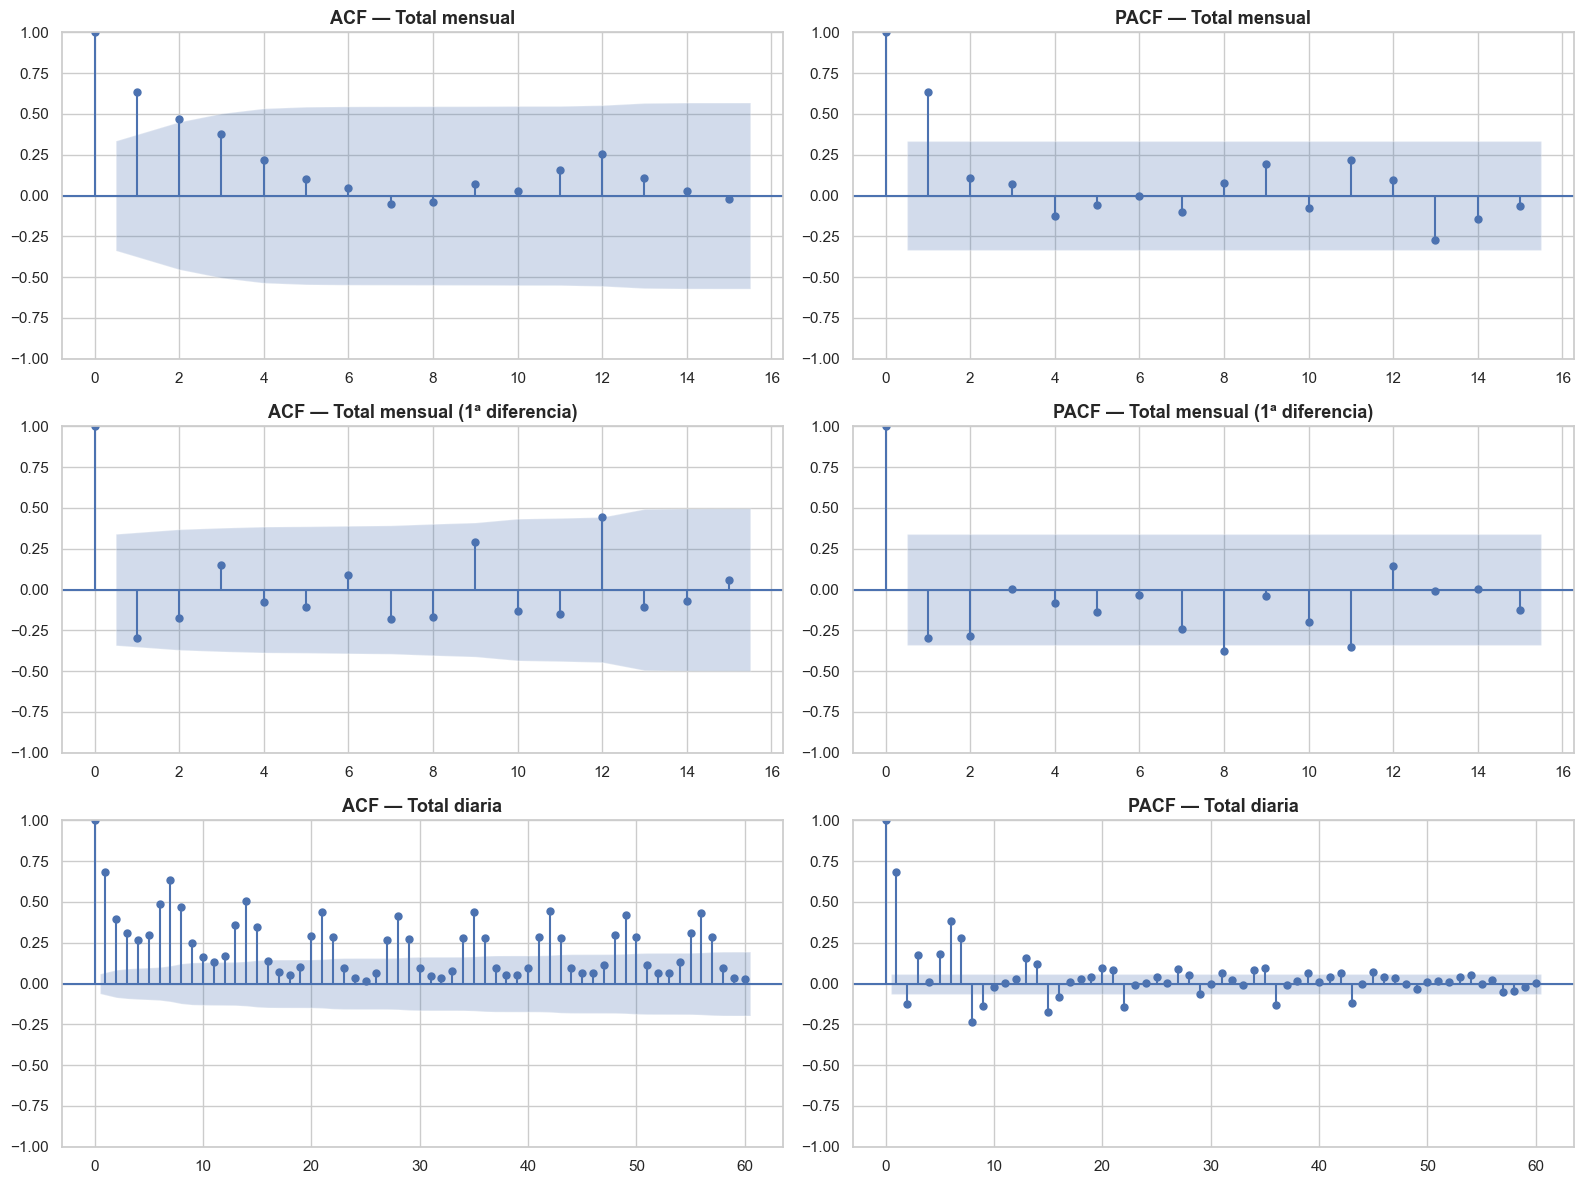

ACF mensual original   lags 1, 2, 3, 12: [np.float64(0.64), np.float64(0.47), np.float64(0.38), np.float64(0.26)]
ACF mensual diferencia lags 1, 12:        [np.float64(-0.29), np.float64(0.45)]
ACF diaria lags 1, 7, 14, 21, 28:         [np.float64(0.68), np.float64(0.64), np.float64(0.51), np.float64(0.44), np.float64(0.41)]


,serie,n,rezagos ACF significativos,rezagos PACF significativos,Ljung-Box p-valor,lag Ljung-Box
0,Total mensual,34,"[1, 2, 3]",[1],0.00,12
1,Total mensual (1ª diferencia),33,[12],"[8, 11]",0.01,12
2,Total diaria,1034,"[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14...","[1, 2, 3, 5, 6, 7, 8, 9, 13, 14, 15, 16, 20, 2...",0.00,14


In [32]:
from statsmodels.stats.diagnostic import acorr_ljungbox

def serie_mensual(filtro):
    """Serie mensual de unidades (34 meses, con 0 en los meses sin venta)."""
    s = df[filtro].groupby("date_block_num")["item_cnt_day"].sum().reindex(range(34), fill_value=0)
    s.index = pd.date_range("2013-01-01", periods=34, freq="MS")
    return s

def analizar_acf(serie, nombre, lags, ax_acf, ax_pacf, lb_lag):
    """Grafica ACF/PACF y devuelve los rezagos significativos y la prueba de Ljung-Box."""
    s = serie.dropna()
    plot_acf(s, lags=lags, ax=ax_acf, title=f"ACF — {nombre}")
    plot_pacf(s, lags=lags, ax=ax_pacf, method="ywm", title=f"PACF — {nombre}")
    banda = 1.96 / np.sqrt(len(s))
    v_acf, v_pacf = acf(s, nlags=lags), pacf(s, nlags=lags, method="ywm")
    return {"serie": nombre, "n": len(s),
            "rezagos ACF significativos": [k for k in range(1, lags + 1) if abs(v_acf[k]) > banda],
            "rezagos PACF significativos": [k for k in range(1, lags + 1) if abs(v_pacf[k]) > banda],
            "Ljung-Box p-valor": round(acorr_ljungbox(s, lags=[lb_lag])["lb_pvalue"].iloc[0], 4),
            "lag Ljung-Box": lb_lag}

resultados_acf = []
fig, axes = plt.subplots(3, 2, figsize=(16, 12))
resultados_acf.append(analizar_acf(mensual["unidades"], "Total mensual", 15, axes[0, 0], axes[0, 1], 12))
resultados_acf.append(analizar_acf(mensual["unidades"].diff(), "Total mensual (1ª diferencia)", 15, axes[1, 0], axes[1, 1], 12))
resultados_acf.append(analizar_acf(diaria["unidades"], "Total diaria", 60, axes[2, 0], axes[2, 1], 14))
plt.tight_layout(); guardar("09a_acf_pacf_total"); plt.show()

v_m = acf(mensual["unidades"], nlags=15)
v_md = acf(mensual["unidades"].diff().dropna(), nlags=15)
v_d = acf(diaria["unidades"], nlags=35)
print("ACF mensual original   lags 1, 2, 3, 12:", [round(v_m[k], 2) for k in [1, 2, 3, 12]])
print("ACF mensual diferencia lags 1, 12:       ", [round(v_md[k], 2) for k in [1, 12]])
print("ACF diaria lags 1, 7, 14, 21, 28:        ", [round(v_d[k], 2) for k in [1, 7, 14, 21, 28]])
pd.DataFrame(resultados_acf)

**Interpretación (9a — serie total):**
- **Mensual original:** la ACF es significativa en los **rezagos 1, 2 y 3** (0.64, 0.47, 0.38) y decae lentamente, típico de una serie **con tendencia**, como confirmaron ADF/KPSS. La PACF solo tiene un corte significativo en el **rezago 1**, lo que sugiere un componente **AR(1)**. Ljung-Box (p < 0.01) confirma que la serie tiene memoria.
- **Mensual diferenciada:** al quitar la tendencia aparece el patrón estacional. La ACF en el **rezago 12 es significativa (0.45)**, es decir, cada mes se parece al mismo mes del año anterior. En la serie original este efecto quedaba "tapado" por la tendencia. El rezago 1 de la diferencia es negativo (−0.29), señal de un posible término **MA(1)**.
- **Diaria:** la ACF es significativa en casi todos los rezagos, con **picos claros en 7, 14, 21, 28...** (0.64, 0.51, 0.44, 0.41), mientras los rezagos intermedios (3–5) son más bajos. Es la huella del **ciclo semanal** (fines de semana altos). El decaimiento lento confirma también la tendencia.
- **¿Hay estacionalidad?** Sí, en dos escalas: **semanal (período 7)** en la serie diaria y **anual (período 12)** en la serie mensual diferenciada.
- **Candidato de modelo para la serie total mensual:** **SARIMA(1,1,1)(0,1,0)₁₂** o **SARIMA(1,1,0)(1,0,0)₁₂**, a comparar contra **Holt-Winters** con tendencia amortiguada. Con 34 datos conviene usar pocos parámetros.

- En la PACF de la serie diferenciada aparecen los rezagos **8 y 11** apenas fuera de la banda (valores negativos). Con solo 33 observaciones se consideran **ruido muestral**, no una estructura real, porque no tienen una explicación de negocio.

### 9b. Series por sucursal, por producto y por sucursal-producto
Selección representativa (el dataset tiene 57 tiendas y más de 21,000 productos):
- **Sucursales:** las 3 tiendas con más ventas que están en el test (31, 25, 28).
- **Productos:** 3 comportamientos distintos: bolsa de marca (20949, consumo continuo), *Diablo III PC* (2808, juego de catálogo) y *GTA V PS3* (3732, juego de lanzamiento).
- **Sucursal-producto:** los mismos tipos en la tienda 31: bolsa (20949), tarjeta PlayStation Store (5822) y *GTA V PS3* (3732).

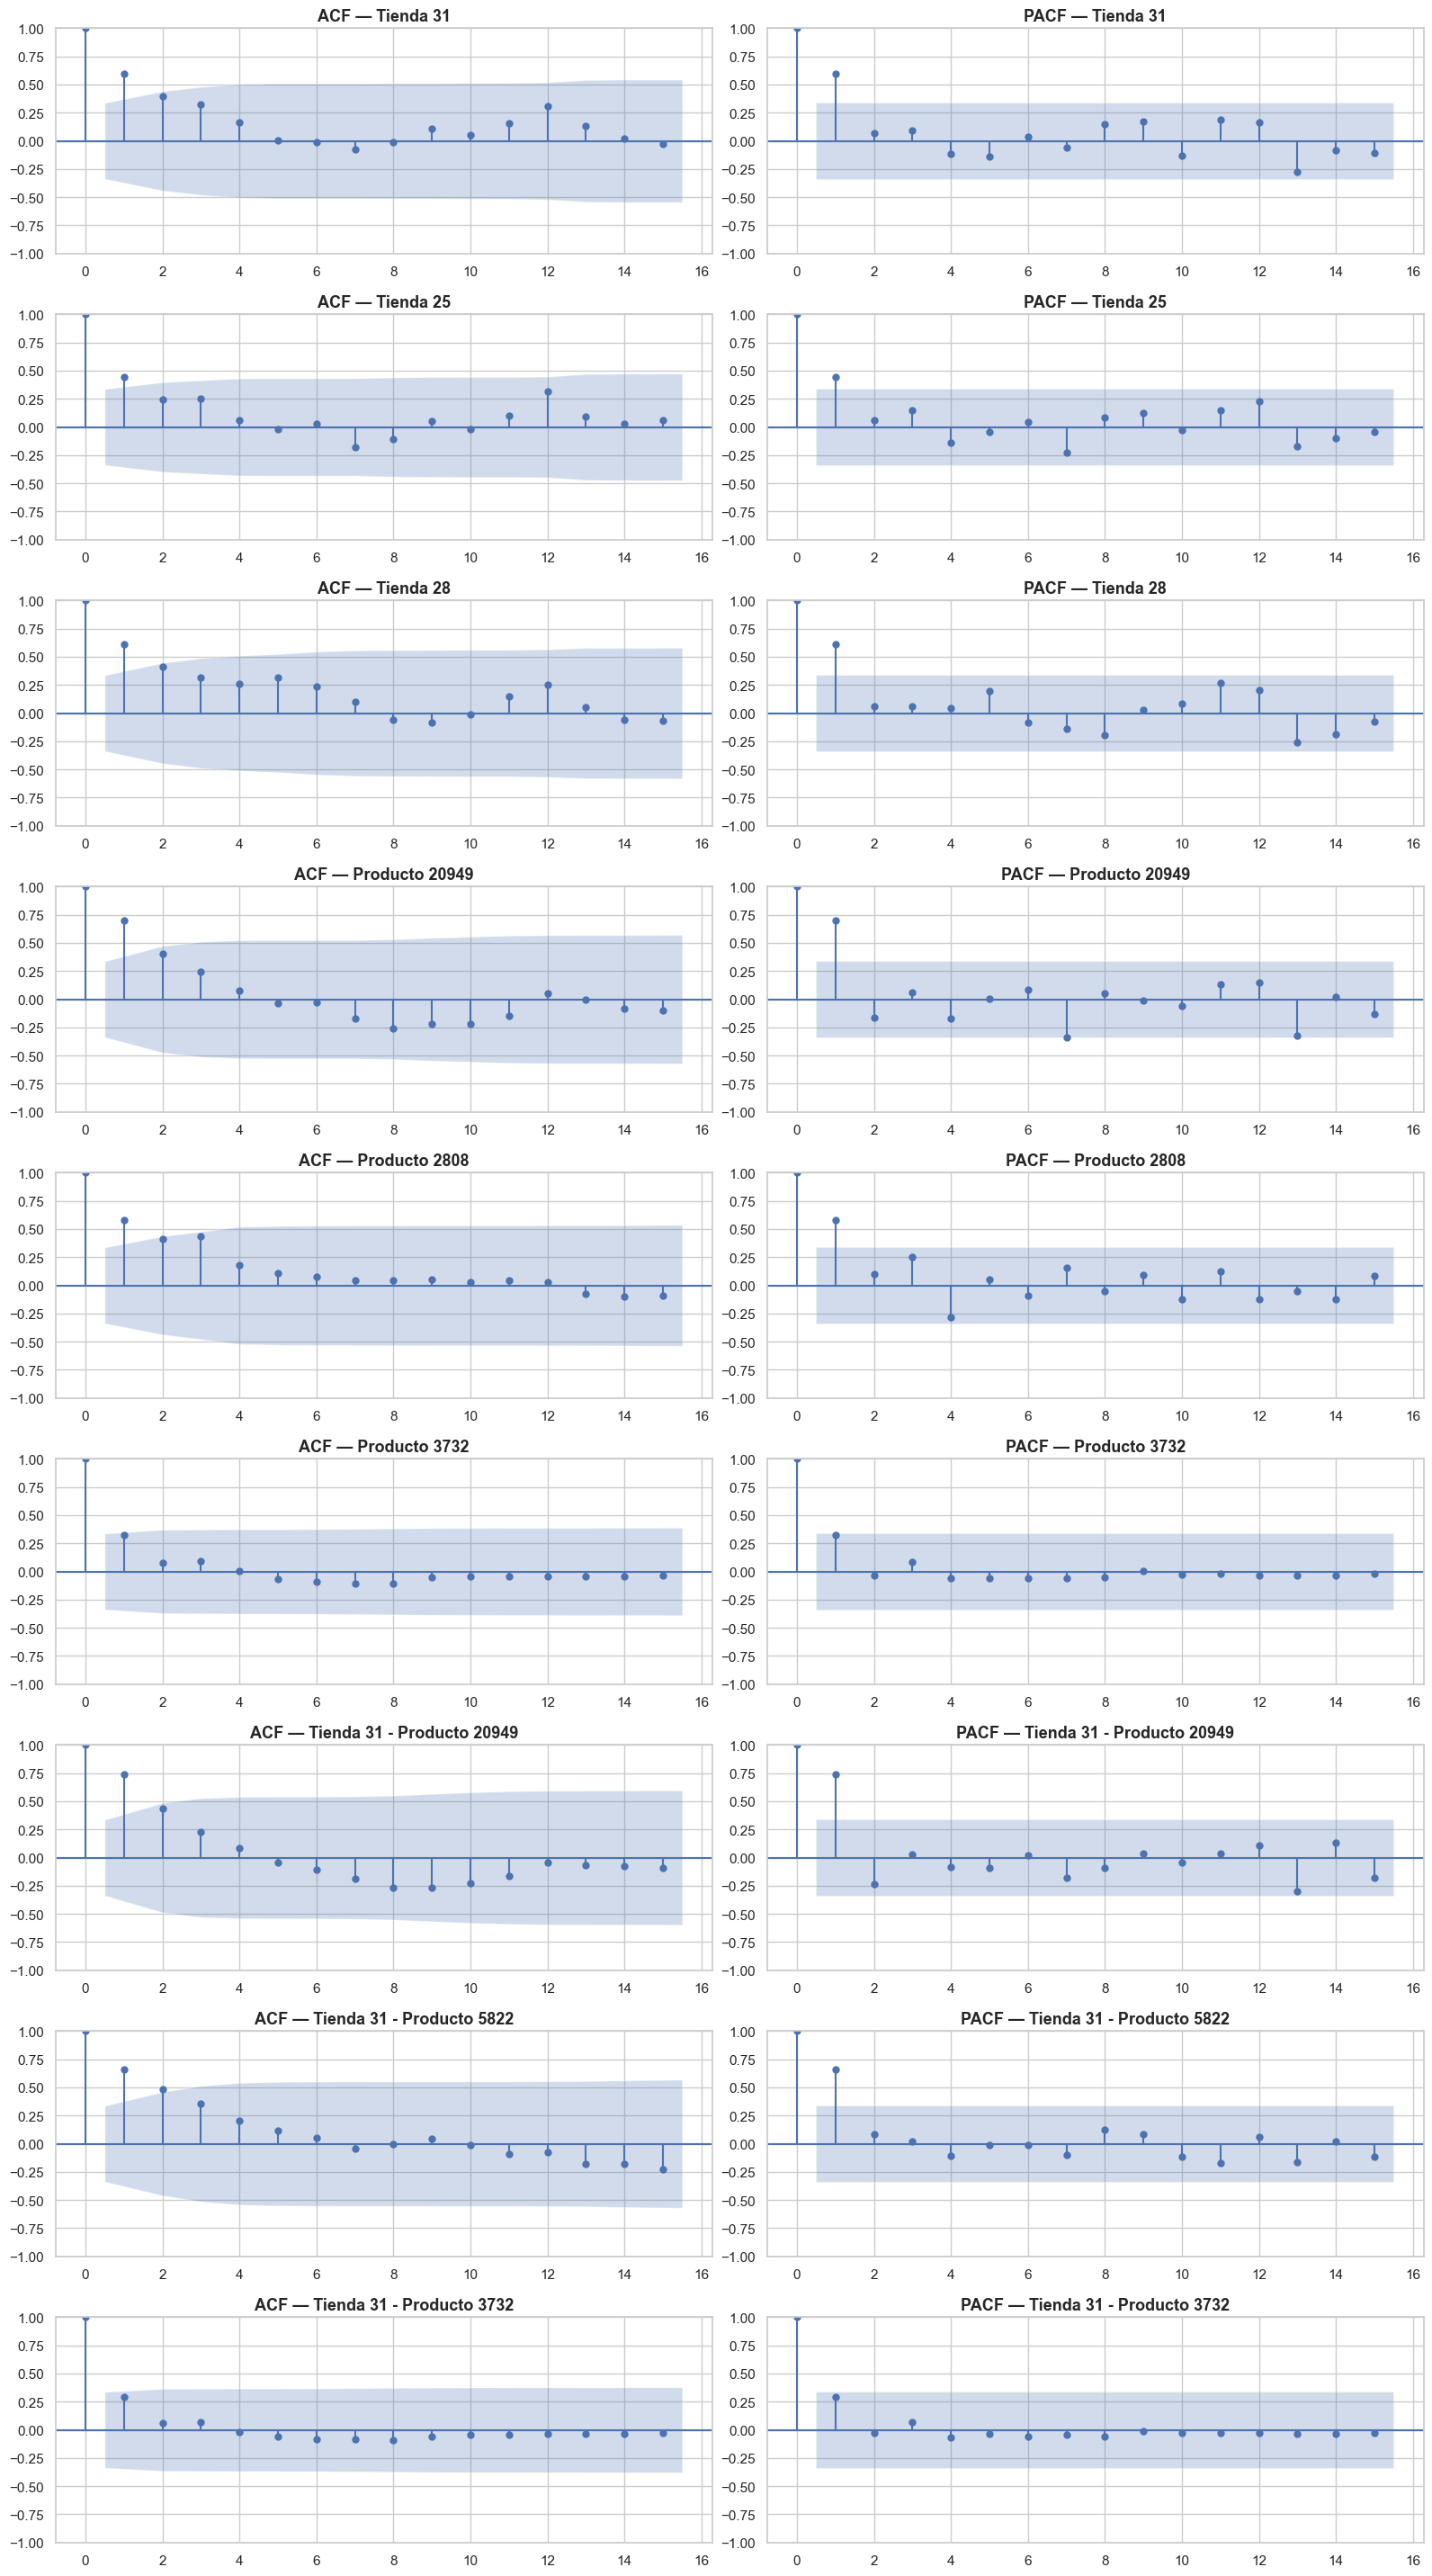

Producto 20949: [0, 0, 0, 255, 3727, 8424, 7269, 7296, 7945, 7738, 8537, 12557, 7329, 6547, 7717, 5875, 5822, 6712, 5976, 6286, 6571, 6547, 7721, 12185, 6869, 3109, 1924, 4097, 3768, 3473, 3347, 3551, 3390, 4078]
Producto 2808: [858, 541, 486, 571, 906, 2727, 1869, 760, 2016, 710, 313, 457, 333, 214, 235, 552, 451, 779, 264, 305, 238, 175, 173, 311, 474, 105, 50, 89, 53, 54, 51, 53, 32, 40]
Producto 3732: [0, 0, 0, 0, 0, 0, 0, 0, 6972, 2753, 929, 1327, 889, 465, 375, 282, 320, 310, 231, 238, 188, 154, 133, 234, 135, 110, 95, 64, 71, 71, 87, 96, 67, 46]
Tienda 31 - Producto 20949: [0, 0, 0, 13, 384, 763, 799, 820, 950, 978, 989, 1305, 899, 941, 776, 597, 602, 625, 528, 591, 639, 634, 772, 1209, 743, 180, 0, 481, 460, 434, 482, 436, 473, 431]
Tienda 31 - Producto 5822: [15, 22, 38, 30, 21, 25, 18, 20, 27, 14, 30, 47, 48, 38, 43, 35, 55, 50, 41, 37, 43, 45, 62, 77, 67, 54, 74, 34, 34, 20, 27, 39, 29, 34]
Tienda 31 - Producto 3732: [0, 0, 0, 0, 0, 0, 0, 0, 548, 195, 61, 89, 44, 29, 19, 21,

,serie,n,rezagos ACF significativos,rezagos PACF significativos,Ljung-Box p-valor,lag Ljung-Box
0,Tienda 31,34,"[1, 2]",[1],0.00,12
1,Tienda 25,34,[1],[1],0.06,12
2,Tienda 28,34,"[1, 2]",[1],0.00,12
3,Producto 20949,34,"[1, 2]","[1, 7]",0.00,12
4,Producto 2808,34,"[1, 2, 3]",[1],0.00,12
5,Producto 3732,34,[],[],0.89,12
6,Tienda 31 - Producto 20949,34,"[1, 2]",[1],0.00,12
7,Tienda 31 - Producto 5822,34,"[1, 2, 3]",[1],0.00,12
8,Tienda 31 - Producto 3732,34,[],[],0.95,12


In [33]:
tiendas_sel = tienda[tienda["en_test"]].nlargest(3, "unidades")["shop_id"].tolist()   # [31, 25, 28]
productos_sel = [20949, 2808, 3732]
pares_sel = [(31, 20949), (31, 5822), (31, 3732)]

grupos = ([(f"Tienda {t}", df["shop_id"] == t) for t in tiendas_sel] +
          [(f"Producto {i}", df["item_id"] == i) for i in productos_sel] +
          [(f"Tienda {t} - Producto {i}", (df["shop_id"] == t) & (df["item_id"] == i)) for t, i in pares_sel])

resultados_9b = []
fig, axes = plt.subplots(len(grupos), 2, figsize=(16, 3.2 * len(grupos)))
for k, (nombre, filtro) in enumerate(grupos):
    resultados_9b.append(analizar_acf(serie_mensual(filtro), nombre, 15, axes[k, 0], axes[k, 1], 12))
plt.tight_layout(); guardar("09b_acf_pacf_tienda_producto"); plt.show()

# Series de producto y de tienda-producto, para entender los resultados
for nombre, filtro in grupos[3:]:
    print(f"{nombre}: {serie_mensual(filtro).astype(int).tolist()}")
pd.DataFrame(resultados_9b)

**Interpretación (9b):**
- **Por sucursal (31, 25, 28):** las tres tiendas grandes se comportan como la serie total: ACF significativa en los **rezagos 1–2** y PACF con un solo corte en el **rezago 1** → estructura **AR(1)** con tendencia. Ljung-Box es significativo en las tiendas 31 y 28 (p < 0.01). En la 25 queda en el límite (p ≈ 0.06), porque su serie es más irregular (caída fuerte en 2014 y recuperación).
- **Por producto**, el resultado depende del **ciclo de vida** del producto:
  - **Bolsa de marca (20949):** artículo de consumo continuo. ACF significativa en los rezagos 1–2 y PACF en el 1 → **muy predecible** con su propio pasado.
  - **Diablo III PC (2808):** juego de catálogo con picos esporádicos (promociones, expansión). ACF en los rezagos 1–3, decayendo a medida que el juego envejece.
  - **GTA V PS3 (3732):** juego de **lanzamiento**. Ceros hasta septiembre de 2013, un pico enorme el mes del lanzamiento (6,972 unidades) y después un decaimiento rápido. **No hay rezagos significativos** (Ljung-Box p ≈ 0.9): la ACF/PACF no captura este patrón de "pico y caída".
- **Por sucursal-producto (tienda 31):**
  - **Bolsa:** igual que a nivel producto, AR(1) claro.
  - **Tarjeta PSN (5822):** demanda estable que crece hacia fines de 2014, con ACF significativa en los rezagos 1–3 → **persistencia** (el mes pasado predice bien el siguiente).
  - **GTA V PS3:** sin autocorrelación significativa; es otra vez el patrón de lanzamiento.
- **¿Estacionalidad en las series individuales?** A nivel tienda o producto, con solo 34 meses, el **rezago 12 no alcanza significancia**. Las series individuales son más ruidosas y la tendencia domina la ACF. La estacionalidad anual se ve mejor en la **serie agregada**.
- **Conclusión para el forecasting:** el **rezago 1 (venta del mes anterior)** es el predictor más fuerte y consistente en casi todos los niveles. Por eso los modelos para esta competencia usan **variables de rezago (lag 1, 2, 3, 12)** de la venta por tienda-producto, por producto y por tienda. Los productos **nuevos o de lanzamiento** no tienen historia útil y requieren información de su **categoría** o de productos similares.

## 10. Insights y conclusiones del EDA
### Cobertura del test: ¿cuántos pares tienda-producto tienen historial?

,pares,%
tipo,,
Par con historial,111471,52.04
"Producto conocido, nuevo en esa tienda",87483,40.84
Producto nuevo (sin historial),15246,7.12


Tiendas en test: 42 | con historial en train: 100 %
Productos en test: 5,100 | nuevos (sin ninguna venta en train): 363
Pares del test que vendieron en el último mes (oct-2015): 13.4 %

Productos nuevos por grupo de categoría (%):
categoria_grupo
Cine             20.40
Regalos          18.50
Música           18.20
Juegos consola   12.40
Libros           12.10


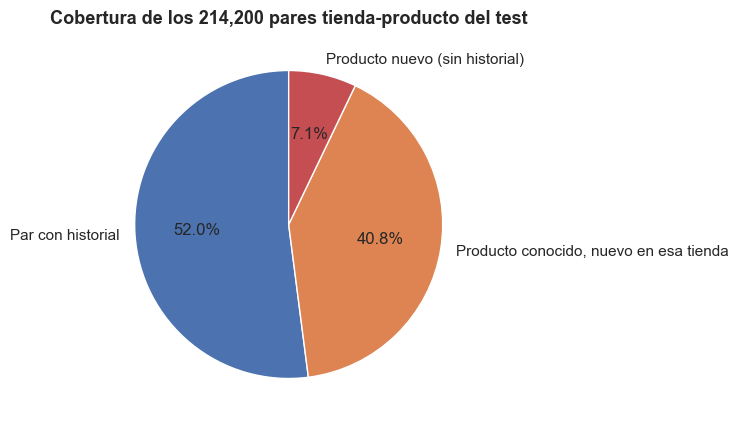

In [34]:
pares_train = df[["shop_id", "item_id"]].drop_duplicates().assign(en_train=True)
cobertura = test_c.merge(pares_train, on=["shop_id", "item_id"], how="left")
cobertura["en_train"] = cobertura["en_train"].fillna(False).astype(bool)
items_train, shops_train = set(df["item_id"]), set(df["shop_id"])

cobertura["tipo"] = np.select(
    [cobertura["en_train"], cobertura["item_id"].isin(items_train)],
    ["Par con historial", "Producto conocido, nuevo en esa tienda"], "Producto nuevo (sin historial)")
resumen_cob = cobertura["tipo"].value_counts().to_frame("pares")
resumen_cob["%"] = resumen_cob["pares"] / len(cobertura) * 100
display(resumen_cob)

print(f"Tiendas en test: {test_c['shop_id'].nunique()} | con historial en train: {test_c['shop_id'].isin(shops_train).mean()*100:.0f} %")
print(f"Productos en test: {test_c['item_id'].nunique():,} | nuevos (sin ninguna venta en train): {len(set(test_c['item_id']) - items_train)}")
ventas_oct = df.loc[df["date_block_num"] == 33, ["shop_id", "item_id"]].drop_duplicates().assign(oct=True)
print(f"Pares del test que vendieron en el último mes (oct-2015): "
      f"{test_c.merge(ventas_oct, on=['shop_id', 'item_id'], how='left')['oct'].notna().mean()*100:.1f} %")

nuevos = (items[items["item_id"].isin(set(test_c["item_id"]) - items_train)]
          .merge(categories[["item_category_id", "categoria_grupo"]], on="item_category_id"))
print("\nProductos nuevos por grupo de categoría (%):")
print((nuevos["categoria_grupo"].value_counts(normalize=True).head(5) * 100).round(1).to_string())

fig, ax = plt.subplots(figsize=(8, 5))
ax.pie(resumen_cob["pares"], labels=resumen_cob.index, autopct="%1.1f%%", startangle=90,
       colors=["#4C72B0", "#DD8452", "#C44E52"], wedgeprops={"edgecolor": "white"})
ax.set_title("Cobertura de los 214,200 pares tienda-producto del test")
guardar("10_cobertura_test"); plt.show()

### 10a. Variables que afectan directamente las ventas

| Variable | Evidencia en el EDA | Efecto |
|---|---|---|
| **Tiempo (tendencia)** | Mann-Kendall p ≈ 10⁻⁶; caída de 130 mil a 76 mil unidades/mes; −2,067 unidades por mes | Las ventas físicas caen de forma sostenida |
| **Mes del año** | Índice estacional: diciembre 147, enero 117, julio 85; Kruskal-Wallis p ≈ 10⁻¹⁹ | Diciembre vende ~47 % más que un mes promedio |
| **Día de la semana** | Sábado 141, domingo 118, lunes 77; Kruskal-Wallis p ≈ 10⁻⁵⁷ | Ciclo semanal fuerte; se diluye al agregar por mes |
| **Tienda** | CV entre tiendas = 0.91; top 5 = 29.5 %; Moscú = 35 % | Define el nivel base y la dirección (crecer o caer) |
| **Categoría** | Pareto 17.8 % / 80 %; Cine y Juegos dominan unidades; consolas dominan ingresos | Cada categoría tiene su propio ciclo de vida |
| **Precio** | Precio medio sube 727 → 1,062 rublos mientras las unidades bajan | Relación inversa volumen-precio; afecta ingreso más que unidades |
| **Lanzamientos y eventos** | Picos de *The Witcher 3*, *Watch Dogs*, *GTA V*; entradas IgroMir | Picos no estacionales, difíciles de predecir |
| **Historia reciente (lag 1)** | PACF corta en el rezago 1 en casi todas las series | La venta del mes anterior es el mejor predictor |

### 10b. Patrones útiles para el modelo de forecasting
1. **Frecuencia mensual:** es la de la variable objetivo y la menos ruidosa (CV 0.27 vs 0.45 diaria).
2. **Tendencia + estacionalidad anual:** la serie mensual no es estacionaria (ADF p = 0.15). Se vuelve estacionaria con **d = 1** y/o **D = 1 (s = 12)**. Candidatos: **SARIMA(1,1,1)(0,1,0)₁₂** y **Holt-Winters con tendencia amortiguada**, siempre parsimoniosos por tener solo 34 meses.
3. **Rezagos:** el **lag 1** es significativo en casi todos los niveles, y el **lag 12** solo en la serie agregada diferenciada. Para un modelo por tienda-producto conviene construir **variables de rezago (1, 2, 3, 12)** a nivel tienda-producto, producto, tienda y categoría.
4. **Noviembre 2015 (mes a predecir):** históricamente vende **~3 % más que el mes promedio** (índice 103) y más que octubre (95), pero con la tendencia decreciente de 2015. Una estimación ingenua para el total sería ligeramente superior a las ~69 mil unidades de octubre 2015.
5. **Cobertura del test:**
   - Solo el **52.0 %** de los 214,200 pares tienda-producto tiene **historial** en el train.
   - El **40.8 %** son productos conocidos pero **nunca vendidos en esa tienda**, y el **7.1 %** (363 productos) son **completamente nuevos**, sobre todo de Cine, Regalos y Música.
   - Las **42 tiendas** del test tienen historial (la 36 solo un mes).
   - Solo el **13.4 %** de los pares vendió algo en octubre 2015.

   **Implicación:** la mayoría de las predicciones serán **cero o casi cero**, y para casi la mitad del test el modelo tendrá que apoyarse en información **agregada** (producto en otras tiendas, categoría, tienda) en lugar de la historia propia del par.
6. **Excluir del entrenamiento** (o tratar aparte) las **13 tiendas cerradas** que no aparecen en el test, y **acotar la venta mensual a [0, 20]**, como hace la métrica de Kaggle.

### 10c. Calidad y preparación del dataset
- **Calidad alta:** 0 % de valores nulos, `date_block_num` 100 % consistente con la fecha y ningún día sin ventas a nivel cadena.
- **Problemas detectados y resueltos:** 6 duplicados exactos eliminados, 1 precio negativo imputado, 3 outliers extremos eliminados, y 3 pares de tiendas duplicadas unificados (0→57, 1→58, 11→10). Se conservó el **99.9997 %** de los registros.
- **Particularidades que el modelo debe considerar:** las devoluciones (0.25 % de los registros) se mantienen porque la venta objetivo es **neta**; los productos caros (consolas) son reales y forman un segmento propio; los nombres de productos están en ruso y se tradujeron categorías y tiendas.
- **Limitaciones:** solo **34 meses** de historia (menos de 3 ciclos anuales), alta **intermitencia** de las series tienda-producto (Gini 0.79) y casi **48 %** del test sin historia propia.
- **Conclusión:** el dataset está **limpio y listo** para la etapa de forecasting. El siguiente paso es construir la **matriz mensual tienda-producto** (incluyendo los meses con venta 0), generar las variables de rezago y calendario identificadas en este EDA y comparar modelos de series de tiempo (SARIMA, Holt-Winters) contra modelos basados en esas variables.